# Trying things out

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import importlib
import cProfile
import itertools
import timeit
import json
import ctmc
import utils
import plot
import networkx as nx

importlib.reload(plot)

<module 'plot' from '/home/tohme/.julia/dev/LLROpt/plot.py'>

## Understanding iterators

In [53]:
a = [np.array([0,1]), np.array([[1,1],[3,6]])]
it = itertools.accumulate(a, ctmc.matmul_r)
b = np.array(list(it))
np.sum(b, axis=1)

array([1., 9.])

In [70]:
setup = """
import numpy as np
import ctmc
import itertools
a = [np.array([0,1])] + [np.array([[1,2],[3,4]])]*100000
it = itertools.accumulate(a, ctmc.matmul_r)
"""

stmt = """
np.log(np.sum(np.array(list(it)), axis=1))
"""

timeit.timeit(stmt, setup, number=1)

0.3747418439888861

In [71]:
stmt2 = """
np.array([np.log(np.sum(i)) for i in it])
"""

timeit.timeit(stmt2, setup, number=1)

0.5998997629940277

## Profiling

### ctmc.ir_full()

In [4]:
import pstats
from pstats import SortKey

nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)
args = (c, dc, on_ind, idist, n, nb, na)

logrates = np.array([1,1,1,1,1,1,1,1])
rates = 10.0 ** logrates

cProfile.run('ctmc.ir_full(rates, *args)', 'irstats')

In [33]:
p = pstats.Stats('irstats')
p.sort_stats(SortKey.CUMULATIVE).print_stats()

Mon Apr 22 16:31:15 2024    irstats

         4999667 function calls in 8.737 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    8.737    8.737 {built-in method builtins.exec}
        1    0.002    0.002    8.737    8.737 <string>:1(<module>)
        1    0.016    0.016    8.735    8.735 /home/tohme/phd/flython/ctmc.py:369(ir_full)
        1    4.267    4.267    4.267    4.267 /home/tohme/phd/flython/ctmc.py:126(generate)
        2    0.107    0.054    2.713    1.357 /home/tohme/phd/flython/ctmc.py:329(ll_full)
   499874    0.901    0.000    2.202    0.000 /home/tohme/phd/flython/ctmc.py:401(matmul_r)
        1    1.671    1.671    1.695    1.695 /home/tohme/phd/flython/utils.py:74(get_residence_times)
   499889    0.315    0.000    1.267    0.000 /home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/numpy/core/fromnumeric.py:2177(sum)
   499898    0.340    0.000    0.919    0.000 /h

In [32]:
p.print_callers(.99)

   Ordered by: internal time
   List reduced from 115 to 114 due to restriction <0.99>

Function                                                                                                              was called by...
                                                                                                                          ncalls  tottime  cumtime
/home/tohme/phd/flython/ctmc.py:126(generate)                                                                         <-       1    4.267    4.267  /home/tohme/phd/flython/ctmc.py:369(ir_full)
/home/tohme/phd/flython/utils.py:74(get_residence_times)                                                              <-       1    1.671    1.695  /home/tohme/phd/flython/ctmc.py:369(ir_full)
/home/tohme/phd/flython/ctmc.py:401(matmul_r)                                                                         <-  499874    0.901    2.202  /home/tohme/phd/flython/ctmc.py:329(ll_full)
{method 'reduce' of 'numpy.ufunc' objects}         

In [ ]:
np.ones((500000, 4, 4))

### ctmc.Generator.generate()

In [19]:
nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)
args = (c, dc, on_ind, idist, n, nb, na)

exp_name = 'outcmaes-diff-limited-log-search-space-general-4s-ir-acc-20240408'
logrates = utils.cmaes_output_to_arr('exps/data/'+exp_name+'/xrecentbest.dat')[-3, 5:13]

rates = 10.0 ** logrates
on = np.where(on_ind)[0]

Q = utils.build_mat(rates, c, nb, na)
C = ctmc.Generator(Q, n, initial_dist=idist)

In [20]:
cProfile.run('C.generate()', sort=0)

         5 function calls in 4.254 seconds

   Ordered by: call count

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    4.254    4.254 {built-in method builtins.exec}
        1    4.254    4.254    4.254    4.254 ctmc.py:126(generate)
        1    0.000    0.000    4.254    4.254 <string>:1(<module>)
        1    0.000    0.000    0.000    0.000 {built-in method numpy.arange}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}




### utils.get_residence_times()

In [75]:
cProfile.run('utils.get_residence_times(C.r[:,0], C.t[:,0], on)', sort=2)

         500004 function calls in 1.724 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    1.724    1.724 {built-in method builtins.exec}
        1    0.002    0.002    1.724    1.724 <string>:1(<module>)
        1    1.698    1.698    1.722    1.722 utils.py:74(get_residence_times)
   500000    0.024    0.000    0.024    0.000 {method 'keys' of 'dict' objects}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}




In [73]:
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)
t_on = np.array(list(res_times['on'].values()))
t_off = np.array(list(res_times['off'].values()))
t_onoff = np.stack((t_on, t_off), axis=1)
t_onoff = np.cumsum(np.concatenate(t_onoff))
t = np.sum(t_on + t_off)

args_ll = (on_ind, t_on, t_off, idist, nb, na)

### ctmc.ll_full()

In [74]:
cProfile.run('ctmc.ll_full(rates, c, *args_ll)', sort=2)

         2223097 function calls in 1.349 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    1.349    1.349 {built-in method builtins.exec}
        1    0.007    0.007    1.349    1.349 <string>:1(<module>)
        1    0.055    0.055    1.342    1.342 ctmc.py:329(ll_full)
   246978    0.443    0.000    1.072    0.000 ctmc.py:372(matmul_r)
   246983    0.149    0.000    0.611    0.000 fromnumeric.py:2177(sum)
   246985    0.160    0.000    0.446    0.000 fromnumeric.py:71(_wrapreduction)
   246991    0.195    0.000    0.195    0.000 {method 'reduce' of 'numpy.ufunc' objects}
        2    0.032    0.016    0.123    0.061 ctmc.py:189(fpt)
        2    0.085    0.043    0.091    0.045 ctmc.py:151(P)
   246985    0.077    0.000    0.077    0.000 fromnumeric.py:72(<dictcomp>)
        1    0.049    0.049    0.057    0.057 utils.py:103(alternate)
        1    0.033    0.033    0.033    0.033 {built-in 

### ctmc.ll_full_fast()

In [61]:
args_ll = (on_ind, t_on, t_off, v_on, nb, na)

cProfile.run('ctmc.ll_full_fast(rates, c, *args_ll)', sort=2)

         292 function calls in 0.404 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.404    0.404 {built-in method builtins.exec}
        1    0.000    0.000    0.404    0.404 <string>:1(<module>)
        1    0.176    0.176    0.403    0.403 ctmc.py:430(ll_full_fast)
        2    0.060    0.030    0.220    0.110 ctmc.py:201(fpt)
        2    0.154    0.077    0.160    0.080 ctmc.py:163(P)
        2    0.004    0.002    0.004    0.002 {method 'flatten' of 'numpy.ndarray' objects}
        5    0.004    0.001    0.004    0.001 {built-in method numpy.zeros}
       13    0.003    0.000    0.003    0.000 {method 'reduce' of 'numpy.ufunc' objects}
        7    0.000    0.000    0.003    0.000 fromnumeric.py:71(_wrapreduction)
        5    0.000    0.000    0.003    0.001 fromnumeric.py:2177(sum)
        2    0.002    0.001    0.002    0.001 numeric.py:932(tensordot)
        2    0.000    0.000  

### ctmc.ir_full_fast()

In [2]:
import pstats
from pstats import SortKey

nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0, 1, 0, 1])
idist = np.array([0.25] * 4)
args = (c, dc, on_ind, idist, n, nb, na)

logrates = np.array([1, 1, 1, 1, 1, 1, 1, 1])
rates = 10.0 ** logrates

cProfile.run('ctmc.ir_full_fast(rates, *args)', 'irstats')
p = pstats.Stats('irstats')
p.sort_stats(SortKey.CUMULATIVE).print_stats()


: 

## Vectorizing get_residence_times

In [76]:
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)

In [22]:
on = np.array([1,3])
on_ = np.outer(on, np.ones(n))

In [23]:
a = np.array([0,1,3,1,2,3,2,4])
b = a / 10
hset = np.array([1,3])
hset_ = np.outer(hset, np.ones(len(a)))

hset_

array([[1., 1., 1., 1., 1., 1., 1., 1.],
       [3., 3., 3., 3., 3., 3., 3., 3.]])

In [25]:
c = np.where(a == hset_, b, 0)
d = np.sum(c, axis=0)
d

array([0. , 0.1, 0.3, 0.1, 0. , 0.3, 0. , 0. ])

In [26]:
c

array([[0. , 0.1, 0. , 0.1, 0. , 0. , 0. , 0. ],
       [0. , 0. , 0.3, 0. , 0. , 0.3, 0. , 0. ]])

In [129]:
d * np.roll(d, 1) > 0

array([False, False,  True,  True, False, False, False, False])

# Interfacing with C

## ctmc.matmul_r() C interface

In [2]:
from ctypes import *
import sys
import os

lib_path = os.path.join(sys.path[0], 'cpython/matmul_%s.so' % (sys.platform))
try:
    matmul_lib = cdll.LoadLibrary(lib_path)
except:
    print('OS %s not recognized' % (sys.platform))

ctypes_matmul_r = matmul_lib.matmul_r
ctypes_accumulate = matmul_lib.accumulate
ctypes_matmul_r.restype = None
ctypes_accumulate.restype = None

In [47]:
# Python

seed = 42
rng = np.random.default_rng(seed)

# rate bounds
log_lb = -5
difflimit = 0.124
log_ub = 5
log_dl = np.log10(difflimit)

#                       k_0^0   k_0^1   k_1^0   k_1^1   k_2^0   k_2^1   k_3^0   k_3^1
log_lbounds = np.array([log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb])
log_ubounds = np.array([log_dl, log_ub, log_dl, log_ub, log_ub, log_ub, log_ub, log_ub])

# set up parameters
nb, na = 1, 1
nstates = 2 ** (nb + na)
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)
on = np.where(on_ind)[0]
off = np.arange(nstates)[~on]

# sample rates
logrates = rng.uniform(log_lbounds, log_ubounds)
rates = 10.0 ** logrates

# build rate matrix and simulate
Q = utils.build_mat(rates, c, nb, na)
C = ctmc.Generator(Q, n, initial_dist=idist)
C.generate()

# residence times in on and off partitions
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)
t_on = np.array(list(res_times['on'].values()))
t_off = np.array(list(res_times['off'].values()))

# only keep nonzero residence times
start_in_on = t_on[0] > 0
t_on = t_on[(t_on > 0)]
t_off = t_off[(t_off > 0)]

# make res time arrays of equal length
minlen = min(len(t_on), len(t_off))
t_on = t_on[:minlen]
t_off = t_off[:minlen]
njumps = minlen

# first-passage time probability densities
R = ctmc.fpt(Q, off, t_on)
S = ctmc.fpt(Q, on, t_off)

R_ = R[..., on, :][..., off]
S_ = S[..., off, :][..., on]

# concatenate into an alternating on-off sequence of matrices
if start_in_on:
    D = utils.alternate(R_, S_)
else:
    D = utils.alternate(S_, R_)

# prepend the initial distribution conditioned on start state
p_on = idist @ on_ind
p_off = idist @ (np.ones(nstates) - on_ind)
D.appendleft(idist[on] / p_on if start_in_on else idist[off] / p_off)

# reduce the sequence to a single vector, rescaling along the way
it = np.array(list(itertools.accumulate(D, ctmc.matmul_r)))

llr_vec_python = np.array(it)
llr_traj_python = np.log(np.sum(it, axis=1))

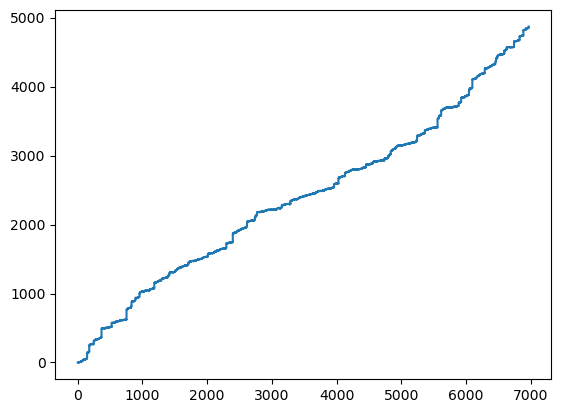

In [4]:
time = np.stack((t_on, t_off), axis=1)
time = np.concatenate(time)
w = 4000
plt.plot(np.cumsum(time)[:w], np.cumsum(llr_traj_python)[:w])

### Toy example

In [25]:
n = 2
m = 2
N_R = 2
N_S = 2
N = N_R + N_S


v = np.array([0,1])
Rlist = np.array([1,0,0,1,0,1,1,0])
Slist = np.array([1,1,2,2,1,1,2,2])

c_m = c_int(m)
c_n = c_int(n)
c_N = c_int(N)
c_v = (c_double * m)(*v)
c_Rlist = (c_double * (m*n*N_R))(*Rlist)
c_Slist = (c_double * (m*n*N_S))(*Slist)
c_vlist = (c_double * (m*N))()

c_M = (c_double * (m*n))(*np.array([0,1,2,3]))
c_w = (c_double * (m))()

In [17]:
ctypes_matmul_r(c_m, c_n, c_v, c_M, c_w)
np.array(c_w)

array([2., 3.])

In [18]:
# C

ctypes_accumulate(c_m, c_n, c_N, c_v, c_Rlist, c_Slist, c_vlist)

In [19]:
c_vlist[:]

[0.0, 1.0, 2.0, 2.0, 0.5, 0.5, 1.5, 1.5]

### Real trajectory

In [57]:
m = len(on)
n = len(off)
N_R = R_.shape[0]
N_S = S_.shape[0]
N = N_R + N_S
v_on = idist[on] / p_on
v_off = idist[off] / p_off

Rlist = R_.flatten()
Slist = S_.flatten()

c_m = c_int(m)
c_n = c_int(n)
c_N = c_int(N)
c_von = (c_double * m)(*v_on)
c_voff = (c_double * n)(*v_off)
c_Rlist = (c_double * (m*n*N_R))(*Rlist)
c_Slist = (c_double * (m*n*N_S))(*Slist)
c_vlist = (c_double * (m*N))()

In [17]:
if start_in_on:
    ctypes_accumulate(c_m, c_n, c_N, c_von, c_Rlist, c_Slist, c_vlist)
else:
    ctypes_accumulate(c_n, c_m, c_N, c_voff, c_Slist, c_Rlist, c_vlist)

In [18]:
a, b = llr_vec_python[1:].flatten(), c_vlist[:]

np.allclose(a, b)

True

### Comparing both implementations in the ctmc file

In [58]:
import time

start = time.time()
ll_traj_python = ctmc.ll_full(rates, c, on_ind, t_on, t_off, v_on, nb, na)
mid = time.time()
ll_traj_c = ctmc.ll_full_fast(rates, c, on_ind, t_on, t_off, v_on, nb, na)
end = time.time()

In [59]:
np.allclose(ll_traj_python[1:], ll_traj_c)

True

In [60]:
print("python: ", mid-start)
print("C: ", end - mid)

python:  1.869136095046997
C:  0.40924930572509766


## ctmc.Generator.generate() C interface

In [2]:
from ctypes import *
import sys
import os

lib_path = os.path.join(sys.path[0], 'cpython/generate_%s.so' % (sys.platform))
try:
    generate_lib = cdll.LoadLibrary(lib_path)
except:
    print('OS %s not recognized' % (sys.platform))

ctypes_generate = generate_lib.generate
ctypes_generate.restype = None

# from ctypes import *
# import sys
# import os

# lib_path = os.path.join(sys.path[0], 'cpython/gillespie_C_%s.so' % (sys.platform))
# try:
#     gillespie_lib = cdll.LoadLibrary(lib_path)
# except:
#     print('OS %s not recognized' % (sys.platform))

# python_gillespie = gillespie_lib.gillespie
# python_gillespie.restype = None

In [4]:
nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)

seed = 45
rng = np.random.default_rng(seed)

# rate bounds
log_lb = -1
difflimit = 0.124
log_ub = 1
log_dl = np.log10(difflimit)

#                       k_0^0   k_0^1   k_1^0   k_1^1   k_2^0   k_2^1   k_3^0   k_3^1
log_lbounds = np.array([log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb])
log_ubounds = np.array([log_dl, log_ub, log_dl, log_ub, log_ub, log_ub, log_ub, log_ub])

# sample rates
logrates = rng.uniform(log_lbounds, log_ubounds)
rates = 10.0 ** logrates
Q = utils.build_mat(rates, c, nb, na)

states, hold_times, t_on, t_off = ctmc.generate(rates, c, n, idist, on_ind, nb, na)

: 

In [3]:
nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0, 1, 0, 1])
idist = np.array([0.25] * 4)
args = (c, dc, on_ind, idist, n, nb, na)

logrates = np.array([1, 1, 1, 1, 1, 1, 1, 1])
rates = 10.0 ** logrates

ns=2 ** (nb + na)
Q=utils.build_mat(rates, c, nb, na).T
K=-np.diag(Q)
k=Q+np.diag(K)
C=np.cumsum(k,0)/K
flattenC=np.transpose(C).flatten()
s0=np.random.default_rng().choice(np.arange(ns), p=idist)

# initialize the ctypes variables
c_K = (c_double * ns)(*K)
c_C = (c_double * (ns**2))(*flattenC)
c_deltat = (c_double * n)()
c_ton = (c_double * n)()
c_toff = (c_double * n)()
c_s = (c_int *n)()
c_on_ind = (c_int *ns)(*on_ind)

# simulate
ctypes_generate(
    c_int(ns), 
    c_int(s0), 
    c_int(n), 
    c_K,
    c_C, 
    c_on_ind,
    c_s, 
    c_deltat,
    c_ton,
    c_toff
)

In [4]:
import scipy

# some tests
assert len(t_on) == len(t_off)

Q = utils.build_mat(rates, c, nb, na)
Q = Q.T
Q_nodiag = Q - np.diag(np.diag(Q))
diagQ = np.diag(Q)
K=-np.diag(Q)
k=Q+np.diag(K)
values, counts = np.unique(states, return_counts=True)

u, s, vh = scipy.linalg.svd((k-np.diag(K))/K)
print(vh[-1,:]/sum(vh[-1,:]))
print(ctmc.P_ss(Q.T))
print(counts / n)

NameError: name 't_on' is not defined

In [51]:
values

array([-1,  0,  1,  2,  3], dtype=int32)

In [36]:
counts

array([     7,      7, 249993, 249993])

# Fully-connected network

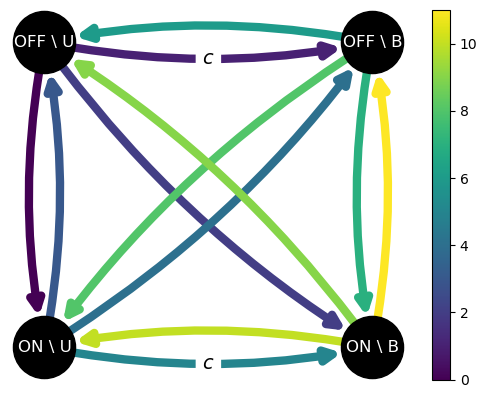

array([[-12.,   0.,  10.,   2.],
       [  3., -57.,   4.,  50.],
       [  6.,   8., -21.,   7.],
       [  9.,  10.,  11., -30.]])

In [4]:
import networkx as nx
importlib.reload(plot)

G = nx.DiGraph()
G.add_nodes_from(range(4))
edges = np.array([(0,1),(0,2),(0,3),
                  (1,0),(1,2),(1,3),
                  (2,0),(2,3),(2,1),
                  (3,0),(3,1),(3,2)])
input_edges = [(0,2), (1,3)]
weights = np.arange(12)[:, None]
base_rates = np.concatenate((edges, weights), axis=1)

plot.draw_circuit(base_rates, input_edges)
utils.build_mat(base_rates, input_edges, 10)

# Tinkering

In [2]:
import numpy as np
import copy

def fpt(Q, hset, t):
    """
    Matrix of PDFs of the first-passage time to hit any state in hset
    """
    nstates = len(Q)
    Q_h = copy.deepcopy(Q)
    Q_h[hset] = np.zeros(nstates)  # rows of hitting set are zeroed

    print(Q_h, '\n')

    print(ctmc.P(Q_h, t))

    return Q_h @ ctmc.P(Q_h, t)

Q = np.array([-1.0, 0.6, 0.4, 
              0.0, -1.5, 1.5, 
              1.0, 1.0, -2.0])

Q = Q.reshape((3, 3))
hset = np.array([0])

t = 1

fpt(Q, hset, t)

[[ 0.   0.   0. ]
 [ 0.  -1.5  1.5]
 [ 1.   1.  -2. ]] 

[[1.         0.         0.        ]
 [0.28212062 0.38383322 0.33404615]
 [0.50481806 0.22269744 0.2724845 ]]


array([[ 0.        ,  0.        ,  0.        ],
       [ 0.33404615, -0.24170368, -0.09234247],
       [ 0.2724845 , -0.06156165, -0.21092286]])

# Getting rid of alternate()

In [61]:
edges = np.array([(0,1), (1,0), (1,2), (2,1)])
input_edges = [(1,0), (1,2)]
on_ind = np.array([1,0,1])
c = 1
dc = 0.1
n = 5
idist = np.ones(3) / 3

logrates = np.random.default_rng().uniform(low=0, high=1, size=4)
rates = 10.0 ** logrates
rates = rates[:, np.newaxis]
weighted_edges = np.concatenate((edges, rates), axis=1)

nstates = len(on_ind)
off_ind = np.ones(nstates) - on_ind
on = np.where(on_ind)[0]
off = np.where(off_ind)[0]

# building the rate matrix and simulating 
Q = utils.build_mat(weighted_edges, input_edges, c)
C = ctmc.Generator(Q, n, initial_dist=idist)
C.generate()

# residence times in on and off partitions
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)
t_on = np.array(list(res_times['on'].values()))
t_off = np.array(list(res_times['off'].values()))

# only keep nonzero residence times
start_in_on = t_on[0] > 0
t_on = t_on[(t_on > 0)]
t_off = t_off[(t_off > 0)]

# make res time arrays of equal length
minlen = min(len(t_on), len(t_off))
t_on = t_on[:minlen]
t_off = t_off[:minlen]

# total duration of trajectory
t = np.sum(t_on + t_off)

# conditional initial distributions
idist_on = idist[on] / (idist @ on_ind)
idist_off = idist[off] / (idist @ off_ind)

if start_in_on:
    args_ll = (on_ind, t_on, t_off, idist_on)
    ind_set = on_ind
    t_set, t_comp = t_on, t_off
    idist_set = idist_on
else:
    args_ll = (off_ind, t_off, t_on, idist_off)
    ind_set = off_ind
    t_set, t_comp = t_off, t_on
    idist_set = idist_off

assert len(t_set) == len(t_comp)

ind_comp = np.ones_like(ind_set) - ind_set
_set = np.where(ind_set)[0]
_comp = np.where(ind_comp)[0]

# matrices of first-passage time PDFs
R = ctmc.fpt(Q, _comp, t_set)
S = ctmc.fpt(Q, _set, t_comp)

# zero-out slices of R except from on->off and from S except from off->on
R[..., _comp, :] = 0
R[..., _set] = 0
S[..., _set, :] = 0
S[..., _comp] = 0

# concatenate into an alternating on-off sequence of matrices
D = utils.alternate(R_, S_)

# prepend the initial distribution conditioned on start state
D.appendleft(idist_set)

# reduce the sequence to a single vector, rescaling along the way
it = np.array(list(itertools.accumulate(D, ctmc.matmul_r)))

ll = np.log(np.sum(it, axis=1))



(2,) (2, 1)
(1,) (1, 2)
(2,) (2, 1)
(1,) (1, 2)


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (5,) + inhomogeneous part.

In [52]:
on_bool = np.array([1,0,1], dtype='bool')
off_bool = np.logical_not(on_bool)

In [76]:
import copy

S1 = copy.deepcopy(S)
R1 = copy.deepcopy(R)


In [77]:
R1[..., _comp, :] = 0
R1[..., _set] = 0
S1[..., _set, :] = 0
S1[..., _comp] = 0

In [81]:
R1

array([[[0.        , 0.64876013, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 1.07623634, 0.        ]],

       [[0.        , 0.46003018, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.90248879, 0.        ]]])

In [82]:
S1

array([[[0.        , 0.        , 0.        ],
        [2.05080202, 0.        , 4.99507377],
        [0.        , 0.        , 0.        ]],

       [[0.        , 0.        , 0.        ],
        [1.36374185, 0.        , 3.32162301],
        [0.        , 0.        , 0.        ]]])

In [104]:
idist = np.ones(3) / 3
idist[_comp] = 0
idist = idist / np.sum(idist)
# np.outer(idist, np.ones(3))
A = np.zeros_like(Q)
A[_set] = idist
A

array([[0.5, 0. , 0.5],
       [0. , 0. , 0. ],
       [0.5, 0. , 0.5]])

In [115]:


D = np.stack((R1, S1), axis=1)
D = np.concatenate(D)
list(itertools.accumulate(D, ctmc.matmul_r))

[array([[0.        , 0.64876013, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 1.07623634, 0.        ]]),
 array([[0.77129351, 0.        , 1.87861527],
        [0.        , 0.        , 0.        ],
        [1.27950851, 0.        , 3.1164585 ]]),
 array([[0.        , 0.29098547, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.48271946, 0.        ]]),
 array([[0.51289458, 0.        , 1.24924115],
        [0.        , 0.        , 0.        ],
        [0.85084727, 0.        , 2.07238186]])]

# Gradient descent
 Intuition: if the cost function g(x) initially grows faster than f(x) along the optimal boundary, then grows slower after some point, then the boundary will be non-concave

In [2]:
import numdifftools as nd

a = 3e-3        # um
D_tf = 7.4      # um^2/s
D_cplx = 0.1    # um^2/s
c = 5.6         # um^-3
dc = 0.1 * c
dl_tf = 4*a*D_tf
ub = 5*7.4/11
max_ir_full = 0.5 * (dc/c)**2 * (1/(c*4*a*D_tf + 1/ub)) ** (-1)

log_ub = np.log10(ub)
log_dl_tf = np.log10(dl_tf)
log_lb = -5 + np.log10(7.4/11)

log_lbounds = np.ones(8) * log_lb
log_ubounds = np.ones(8) * log_ub

# diff-limited upper bounds
log_ubounds[0] = log_dl_tf
log_ubounds[2] = log_dl_tf

# lower bounds
log_lbounds[0] = min(log_lb, log_dl_tf - 1)
log_lbounds[2] = min(log_lb, log_dl_tf - 1)

lbounds = 10.0 ** log_lbounds
ubounds = 10.0 ** log_ubounds
bounds = [log_lbounds, log_ubounds]

########### Circuit
edges = np.array([(0,2), (0,1), (1,3), (1,0), (2,0), (2,3), (3,1), (3,2)])#, (0,3), (3,0)])
input_edges = [(0,2), (1,3)]#, (0,3)]

########### CMA parameters
maxfevals = 10000
sigma0 = (log_ub) / 4
x0 = (log_ubounds + log_lbounds) / 2
# x0 = np.array([-1.05,-4,-1.05,0.69,-4,0.69,0.69,-4])    # true optimum
weighted_eges = np.concatenate((edges, x0[:, np.newaxis]), axis=1)

on_ind = np.array([0,1,0,1])
betas = np.logspace(-8, -3, 30)

In [45]:
setup = """
import importlib
import numpy as np
import ctmc
importlib.reload(ctmc)
import timeit

Q = np.array([[-2, 2], [2, -2]])
weighted_edges = np.array([(0,1,2), (1,0,2)])
input_edges = np.array([(0,1)])
c = 1.0000000001
on_ind = np.array([0,1])
t_set = np.array([1,2,3])
t_comp = np.array([2,3,4])
ind_set = np.array([0,1])
idist_set = np.array([0.5])
"""

timeit.timeit("ctmc.ll_full(weighted_edges, input_edges, c, ind_set, t_set, t_comp, idist_set)", setup=setup, number=10000)

1.5585023909807205

In [2]:
import importlib
import numpy as np
import ctmc
importlib.reload(ctmc)
import timeit
import matplotlib.pyplot as plt

weighted_edges = np.array([(0,1,0.5), (1,0,2)])
input_edges = [(0,1)]
c = 1
dc = 0.1
on_ind = np.array([0,1])
idist = np.ones(2) / 2
n = 1000

N = 1000
acc = 0
for i in range(N):
    t_on, t_off, llr = ctmc.ir_full(weighted_edges, input_edges, c, dc, on_ind, idist, n)
    acc += llr[-1] / np.sum((t_on, t_off))

acc / N

# fig, ax = plt.subplots(1,1)

# ax.hist(times, density=True)
# ax.plot()

# times = np.zeros(3)

# for i in range(n):
#     si = G.r[i, 0]
#     times[si] += G.t[i, 0]

# times /= np.sum(G.t)
# times

0.0018624739325114993

In [98]:
llr.shape

(5001,)

In [2]:
llr

array([0.        , 0.0651039 , 0.0651039 , ..., 3.67476954, 3.61412779,
       3.61412779])

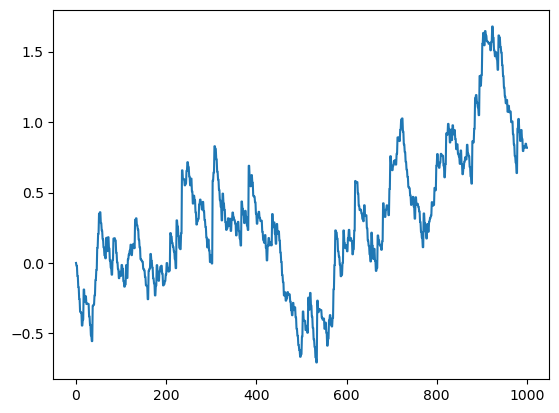

In [7]:
plt.plot(llr)

# Problem with pareto fronts

In [6]:
# try to isolate the problem(s)
# 1. optima should be the same under rescaling of the parameter bounds
# 2. beta should be the slope of the curve

# function to minimize
def f(x):
    return -x[0]**2 - x[1]**2

# constraint
def g(x, c):
    return x[1] - c*x[0]

def L(x, c, beta):
    return f(x) + beta*g(x, c)

# bounds
lb = [0, 0]
ub = [5, 5]
bounds = [lb, ub]

# lagrange multiplier
betas = np.linspace(0, 10, 20)
c = 1

# cma settings
x0 = [1,1]
sigma0 = 0.25
maxfevals = 5000
output = []

for key, beta in enumerate(betas):

    args = (c, beta)

    opts = {'maxfevals': maxfevals,
            'bounds': bounds,
            'verb_append': 0}

    xopt, es = cma.fmin2(L, x0, sigma0, options=opts, args=args)
    output.append(es)

(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=346627, Wed Jul 17 16:27:56 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 -3.369458931239090e+00 1.0e+00 2.87e-01  3e-01  3e-01 0:00.0
    2     12 -3.789485792000014e+00 1.3e+00 3.11e-01  3e-01  3e-01 0:00.0
    3     18 -4.441100587172597e+00 1.4e+00 3.08e-01  3e-01  3e-01 0:00.0
   79    474 -5.000000000000000e+01 1.3e+00 3.87e-05  3e-08  3e-08 0:00.0
termination on tolfun=1e-11 (Wed Jul 17 16:27:56 2024)
final/bestever f-value = -5.000000e+01 -5.000000e+01 after 475/436 evaluations
incumbent solution: [5.0, 5.0]
std deviation: [2.8691644079836216e-08, 2.6366114758051917e-08]
(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=404291, Wed Jul 17 16:27:56 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 -2.760281284998398e+00 1.0e+00 2.53e-01  3e-01  3e-01 0:00.0
    2     12 -4.061943276321189e+00 1.1e+00 3.52e-01  3e-01  5e-01 0:00.0
   

/home/tohme/phd/flython/cma/utilities/utils.py:343: UserWarning: sigma change np.exp(1.0184914363684265) = 2.7690143771826414 clipped to np.exp(+-1) (class=CMAAdaptSigmaCSA method=update iteration=2)
  warnings.warn(msg + ' (' +


   87    522 -7.500000000000000e+01 1.6e+00 1.62e-05  7e-09  7e-09 0:00.0
termination on tolflatfitness=1 (Wed Jul 17 16:27:58 2024)
final/bestever f-value = -7.500000e+01 -7.500000e+01 after 523/469 evaluations
incumbent solution: [5.0, 5.993424004088332e-16]
std deviation: [6.6629557971131726e-09, 6.946163001706939e-09]


In [10]:
es = output[-1]
res = es.result
res[0]

array([5.00000000e+00, 1.75551817e-16])

In [48]:
def constraint(x, mx, my, const):
    return x[0]*mx + x[1]*my - const

def detfun(x, cx, cy, mx, my, const, beta=0):
    return (x[0] - cx)**2 + (x[1] - cy)**2 + beta * np.abs(constraint(x, mx, my, const))

def stochfun(x, a, b, l):
    rng = np.random.default_rng()
    x += rng.normal(0,l, x.shape)
    return (x[0] - a)**2 + (x[1] - b)**2 

(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=339777, Wed Jul 17 17:01:21 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 1.872592983042352e-01 1.0e+00 2.81e-01  2e-01  3e-01 0:00.0
    2     12 3.279515646502942e-02 1.3e+00 3.20e-01  3e-01  3e-01 0:00.0


    3     18 3.950734510349879e-02 1.7e+00 3.22e-01  3e-01  3e-01 0:00.0
   63    378 2.304942742306854e-14 1.3e+00 2.21e-05  7e-08  8e-08 0:00.0
termination on tolfun=1e-11 (Wed Jul 17 17:01:21 2024)
final/bestever f-value = 2.696152e-14 4.340364e-16 after 379/323 evaluations
incumbent solution: [0.4999998650549818, 0.500000093548711]
std deviation: [6.571230258158016e-08, 7.675954636730959e-08]
(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=323719, Wed Jul 17 17:01:21 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 3.441907222225167e-01 1.0e+00 3.99e-01  4e-01  5e-01 0:00.0
    2     12 3.149736856082032e-01 1.5e+00 3.72e-01  4e-01  4e-01 0:00.0
    3     18 3.173846187526304e-01 1.4e+00 3.20e-01  3e-01  3e-01 0:00.0
   70    420 3.086419753086422e-01 1.4e+00 1.27e-05  2e-08  2e-08 0:00.0
termination on tolfun=1e-11 (Wed Jul 17 17:01:21 2024)
final/bestever f-value = 3.086420e-01 3.086420e-01 after 421/406 evaluations
incumbent solu

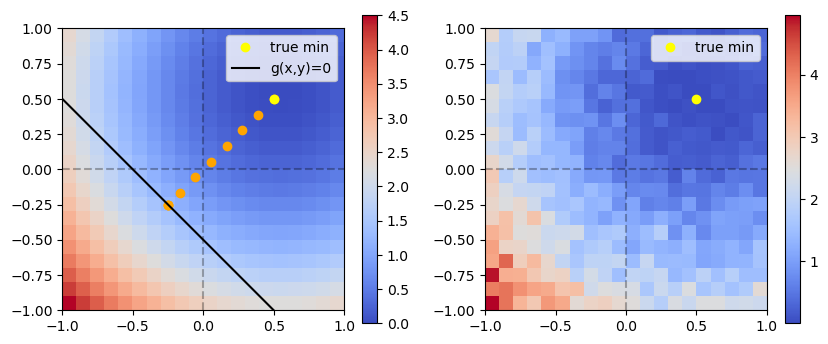

In [58]:
import matplotlib.cm as cm

# parameters
dx = 0.1     # spatial resolution
ub = 1       # upper bound
lb = -1      # lower bound
cx = 0.5     # x-coordinate of center
cy = 0.5   # y-coordintate of center
mx = 1
my = 1
const = -0.5
noise = 0.1  # noise level

x = np.arange(lb, ub, dx)
y = np.arange(lb, ub, dx)
X, Y = np.meshgrid(x, y)
detZ = detfun(np.array([X, Y]), cx, cy, mx, my, const)
stochZ = stochfun(np.array([X, Y]), cx, cy, noise)

# CMA-ES parameters
bounds = np.array([[lb, lb], [ub, ub]])
x0 = np.zeros(2)
sigma0 = 0.3
opts = {'maxfevals': 1000,
        'verb_filenameprefix':'exps/data/outcmaes-test/'}
betas = np.linspace(0, 2, 10)
solutions = []

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

for key, beta in enumerate(betas):
    xopt, es = cma.fmin2(detfun, x0, sigma0, args=(cx, cy, mx, my, const, beta), options=opts)
    ax[0].plot(xopt[0], xopt[1], 'o', color='orange')
    solutions.append(es)

im0 = ax[0].imshow(detZ, interpolation='none', origin='lower', cmap=cm.coolwarm, extent=(lb, ub, lb, ub))
im1 = ax[1].imshow(stochZ, interpolation='none', origin='lower', cmap=cm.coolwarm, extent=(lb, ub, lb, ub))
ax[0].plot(cx, cy, 'o', color='yellow', label='true min')
ax[0].plot(x, (const - x*mx) / my, color='black', label='g(x,y)=0')
ax[1].plot(cx, cy, 'o', color='yellow', label='true min')
ax[0].axhline(y = 0, linestyle='dashed', color='black', alpha=0.3)
ax[1].axhline(y = 0, linestyle='dashed', color='black', alpha=0.3)
ax[0].axvline(x = 0, linestyle='dashed', color='black', alpha=0.3)
ax[1].axvline(x = 0, linestyle='dashed', color='black', alpha=0.3)
ax[0].set_xlim(-1,1)
ax[0].set_ylim(-1,1)

_ = fig.colorbar(im0, orientation='vertical', shrink=1)
_ = fig.colorbar(im1, orientation='vertical', shrink=1)
ax[0].legend()
ax[1].legend()

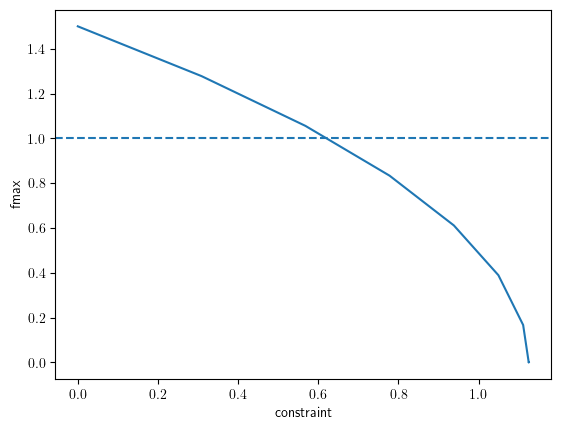

In [64]:
fig, ax = plt.subplots(1,1)

fopts = []
constr = []
fmax = 1

for key, beta in enumerate(betas):
    es = solutions[key]
    res = es.result
    fopts.append(res[1])
    constr.append(constraint(res[0], mx, my, const))

ax.plot(fopts, constr)
ax.set_ylabel('fmax')
ax.set_xlabel('constraint')
ax.axhline(y=fmax, linestyle='dashed')

# IR-EPr Pareto front

In [142]:
a = 3e-3        # um
D_tf = 7.4      # um^2/s
cr = 5.6         # um^-3
dc = 0.1 * cr
dl_tf = 4*a*D_tf
ub = 5
max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)

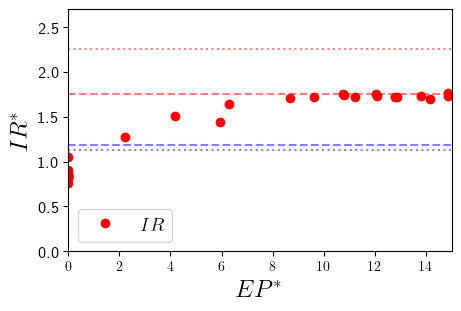

In [144]:
import matplotlib.pyplot as plt

dirname = '20241107/ir-ep'
skipkeys = [1, 15]

# dirname = '20241111/2bs-ir-ep'
# skipkeys = [1, 4, 6, 7, 15, 19, 26, 28, 31]

nedges = 8
irkey = nedges
data_full = {}
data_acc = {}
data_acc_proc = {}
ncpus = 32
nparams_per_cpu = 1
betakeys = np.arange(1, ncpus+1)


for cpukey in range(1, ncpus+1):
    if cpukey not in skipkeys:
        # data_full_proc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_vs_ep_pareto_4s_beta{}.json'.format(dirname, cpukey)))
        # data_acc_proc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_acc_vs_ep_pareto_4s_beta{}.json'.format(dirname, cpukey)))
        data_full_proc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_vs_ep_pareto_pid{}.json'.format(dirname, cpukey)))
        # # data_acc_proc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_acc_vs_ep_pareto_pid{}.json'.format(dirname, cpukey)))

        for k in range(1, nparams_per_cpu+1):
            betakey = (cpukey - 1)*nparams_per_cpu + k
            if betakey not in skipkeys:
                data_full[betakey] = data_full_proc[str(betakey)]
                # data_acc[betakey] = data_acc_proc[str(betakey)]

# nvals = len(data_acc.keys())

irvals_full = [data_full[i][irkey] for i in betakeys if i not in skipkeys]
epvals_full = [data_full[i][irkey+1] for i in betakeys if i not in skipkeys]
irvals_full_std = [data_full[i][irkey+2] for i in betakeys if i not in skipkeys]
# # irvals_acc = [data_acc[i][8] for i in betakeys]
# # epvals_acc = [data_acc[i][9] for i in betakeys]
# epvals_acc.append(15.2)
# epvals_acc.append(16.8)
# # irvals_acc.append(irvals_acc[-1])
# # irvals_acc.append(irvals_acc[-1])

plt.rcParams['text.usetex'] = True

fig, ax = plt.subplots(1,1, layout='constrained', figsize=(4.5,3))

# # # ax.plot(epvals_acc, irvals_acc, marker='none', color='blue', label=r'$IR_{acc}$')
ax.errorbar(epvals_full, irvals_full,  marker='o', linestyle='none', capsize=2, color='red', label=r'$IR$')
# ax.plot(np.array(epvals_acc), np.array(irvals_acc), marker='', color='red', alpha=0.5)
ax.axhline(y=max_ir_full, color='red', linestyle='dotted', alpha=0.5)
ax.axhline(y=0.00176, color='red', linestyle='dashed', alpha=0.5)
ax.axhline(y=max_ir_full/2, color='blue', linestyle='dotted', alpha=0.5)
ax.axhline(y=0.001186, color='blue', linestyle='dashed', alpha=0.5)
ax.set_ylim(0,0.0027)
ax.set_xlim(0, 15)
ax.set_yticks(np.linspace(0,2.5e-3, 6))
ax.set_yticklabels(np.linspace(0,2.5, 6), fontsize=12)
# ax.set_xticks(np.arange(0,10,2))
# ax.set_xticklabels(np.arange(0,10,2), fontsize=12)
ax.set_ylabel(r"$IR^*$", fontsize=18)
ax.set_xlabel(r"$EP^*$", fontsize=18)
# ax.yaxis.set_label_coords(-0.1,0.75)
# ax.xaxis.set_label_coords(0.8, -0.13)
ax.legend(fontsize=14)
# ax.set_xscale('log')
epvals = np.linspace(0, 10, 100)

# betas = np.linspace(1.5e-4, 1e-5, 20)

# for beta in betas:
#     ax.plot(epvals, beta*epvals+1e-3)

In [ ]:
edges = [(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
         (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]
input_edges = [(1,3), (2,4), (5,1), (6,2)]
on_ind = np.array([0,1,0,1,0,1])

G = nx.DiGraph()
for u, v, w in wedges_acc_lin:
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)]) for i in G.nodes()]

node_labels = {0: r'FU',
                1: r'NU',
                2: r'FBR',
                3: r'NBR',
                4: r'FBW',
                5: r'NBW'}

node_numbers = {0: r'1',
                1: r'2',
                2: r'3',
                3: r'4',
                4: r'5',
                5: r'6'}

input_labels = {(0,4):"cw",
                (0,2):"cr",
                (1,5):"cw",
                (1,3):"cr"}

figcirc, ax, G = plot.draw_circuit(wedges_acc,
                                   iedges, 
                                   node_labels=node_numbers, 
                                   input_labels=input_labels,
                                   bottom_set=[5,1,3],
                                   node_size=1000,
                                   node_color=node_color,
                                   title="IR_acc",
                                   dims=(5,2.8))

In [146]:
fig.savefig('/home/tohme/phd/flython/plots/ir-ep-pareto-20241114.pdf')

In [180]:
dirname = 'plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig(dirname+'/pareto_ir_ep.pdf')

In [86]:
fig.savefig('plots/optimal_circuit_4s_acc_beta0.pdf')

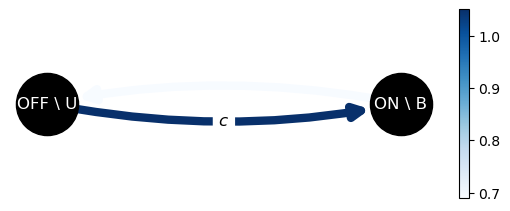

In [206]:
importlib.reload(plot)

logrates = np.array([0.69, 1.05])

edges2s = np.array([(1,0),(0,1)])
input_edges2s = [(0,1)]
weighted_edges_acc2s = np.concatenate((edges2s, logrates[:, None]), axis=1)
node_labels = {0: r'OFF \ U', 1: r'ON \ B'}
fig, ax = plot.draw_circuit(weighted_edges_acc2s, input_edges2s, node_labels=node_labels, align="vertical", bottom_set=[0], dims=(5,2))

In [207]:
fig.savefig('plots/optimal_circuit_2s_irfull.pdf')

# Modeling specificity with one binding site

### $IR_{mix}$ vs. threshold on $k_u^w/k_u^c \geq r$

In [2]:
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

data_acc = {}
data_full = {}

plt.rcParams['text.usetex'] = True

fig, ax = plt.subplots(1,1, layout='constrained')

date = 20240914
gammas = [2.5, 10]
wvals = [10]
markers = ['o', 'd', '+']
colors = ['C0', 'C1', 'C2']
nbetas = 15
ngammas = 2
nws = 1

for keyb in range(1, 16):

    data_acc[str(keyb)] = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_acc_mix_vs_pure_pareto_beta{}.json'.format(date, keyb)))
    data_full[str(keyb)] = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_mix_vs_pure_pareto_beta{}.json'.format(date, keyb)))

    data_acc[str(keyb)] = data_acc[str(keyb)][str(keyb)]
    data_full[str(keyb)] = data_full[str(keyb)][str(keyb)]

for (i, gamma) in enumerate(gammas):
    for (j, w) in enumerate(wvals):

        keyg = str(i+1)
        keyw = str(j+1)

        xopt = [data_acc[str(k)][keyg][keyw][:8] for k in np.arange(1, nbetas+1, 1)]
        ir_acc_mix = [data_acc[str(k)][keyg][keyw][8] for k in np.arange(1, nbetas+1, 1)]
        ir_acc_pure = [data_acc[str(k)][keyg][keyw][9] for k in np.arange(1, nbetas+1, 1)]
        ir_full_mix = [data_full[str(k)][keyg][keyw][8] for k in range(1, nbetas+1)]
        ir_full_pure = [data_full[str(k)][keyg][keyw][9] for k in range(1, nbetas+1)]
        ir_full_mix_std = [data_full[str(k)][keyg][keyw][10] for k in range(1, nbetas+1)]
        ir_full_pure_std = [data_full[str(k)][keyg][keyw][11] for k in range(1, nbetas+1)]

        ax.errorbar( ir_acc_pure, ir_acc_mix, marker=markers[i], color=colors[j], linestyle='none', markersize=6)#, label=r"$IR_{acc}$")
        ax.errorbar( ir_full_pure, ir_full_mix, ir_full_mix_std, ir_full_pure_std, linestyle='none',
                    marker=markers[i], color='C2', label=r"$IR_{full}$")

        ax.set_ylabel(r"$IR_{pure}$ (bits/s)", fontsize=18)
        ax.set_xlabel(r"$IR_{mix}$ (bits/s)", fontsize=18)
        irvals = np.linspace(0, 2e-3, 50)
        # ax.plot(irvals, irvals, linestyle='dashed', color='black', alpha=0.5)

        # ax.set_ylim(0, 0.003)

h1 = mpatches.Patch(color=colors[j])  
wlabels = list(zip(*[(mpatches.Patch(color=colors[j]), 'w = {}'.format(w)) for (j,w) in enumerate(wvals)]))
gammalabels = list(zip(*[(Line2D([0], [0], color='gray', marker=markers[i]),r"$\gamma = {}$".format(g)) for (i,g) in enumerate(gammas)]))
# ax.legend(wlabels[0]+gammalabels[0], wlabels[1]+gammalabels[1], loc='lower right')
ax.legend(gammalabels[0], gammalabels[1], loc='lower right')
# ax.set_ylim(0, 0.0013)
# ax.set_xlim(0, 0.0012)
_=ax.set_title(r"$\gamma = \frac{k_{U}^W}{k_{U}^R} $, $\frac{c}{w} = 10$", fontsize=20)


### $IR_{mix}$ vs. $\langle \frac{P(ON \vert \text{cognate})}{P(ON \vert \text{non-cognate})} \rangle$

In [3]:
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches

data_acc = {}
data_full = {}

plt.rcParams['text.usetex'] = True

fig, ax = plt.subplots(1,1, layout='constrained')

date = 20240914
gammas = [2.5, 10]
wvals = [10]
markers = ['o', 'd', '+']
colors = ['C0', 'C1', 'C2']
nbetas = 15
ngammas = 2
nws = 1

for keyb in range(1, 16):

    data_acc[str(keyb)] = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_acc_mix_vs_pure_pareto_beta{}.json'.format(date, keyb)))
    data_full[str(keyb)] = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_mix_vs_pure_pareto_beta{}.json'.format(date, keyb)))

    data_acc[str(keyb)] = data_acc[str(keyb)][str(keyb)]
    data_full[str(keyb)] = data_full[str(keyb)][str(keyb)]

for (i, gamma) in enumerate(gammas):
    for (j, w) in enumerate(wvals):

        keyg = str(i+1)
        keyw = str(j+1)

        xopt = [data_acc[str(k)][keyg][keyw][:8] for k in np.arange(1, nbetas+1, 1)]
        ir_acc_mix = [data_acc[str(k)][keyg][keyw][8] for k in np.arange(1, nbetas+1, 1)]
        ir_acc_pure = [data_acc[str(k)][keyg][keyw][9] for k in np.arange(1, nbetas+1, 1)]
        ir_full_mix = [data_full[str(k)][keyg][keyw][8] for k in range(1, nbetas+1)]
        ir_full_pure = [data_full[str(k)][keyg][keyw][9] for k in range(1, nbetas+1)]
        ir_full_mix_std = [data_full[str(k)][keyg][keyw][10] for k in range(1, nbetas+1)]
        ir_full_pure_std = [data_full[str(k)][keyg][keyw][11] for k in range(1, nbetas+1)]

        ax.errorbar( ir_acc_pure, ir_acc_mix, marker=markers[i], color=colors[j], linestyle='none', markersize=6)#, label=r"$IR_{acc}$")
        ax.errorbar( ir_full_pure, ir_full_mix, ir_full_mix_std, ir_full_pure_std, linestyle='none',
                    marker=markers[i], color='C2', label=r"$IR_{full}$")

        ax.set_ylabel(r"$IR_{pure}$ (bits/s)", fontsize=18)
        ax.set_xlabel(r"$IR_{mix}$ (bits/s)", fontsize=18)
        irvals = np.linspace(0, 2e-3, 50)
        # ax.plot(irvals, irvals, linestyle='dashed', color='black', alpha=0.5)

        # ax.set_ylim(0, 0.003)

h1 = mpatches.Patch(color=colors[j])  
wlabels = list(zip(*[(mpatches.Patch(color=colors[j]), 'w = {}'.format(w)) for (j,w) in enumerate(wvals)]))
gammalabels = list(zip(*[(Line2D([0], [0], color='gray', marker=markers[i]),r"$\gamma = {}$".format(g)) for (i,g) in enumerate(gammas)]))
# ax.legend(wlabels[0]+gammalabels[0], wlabels[1]+gammalabels[1], loc='lower right')
ax.legend(gammalabels[0], gammalabels[1], loc='lower right')
# ax.set_ylim(0, 0.0013)
# ax.set_xlim(0, 0.0012)
_=ax.set_title(r"$\gamma = \frac{k_{U}^W}{k_{U}^R} $, $\frac{c}{w} = 10$", fontsize=20)


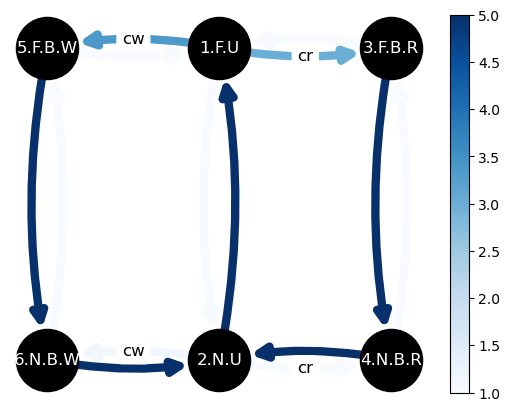

In [7]:
importlib.reload(plot)

# Building the circuit

a = 3e-3        # um
D_tf = 7.4      # um^2/s
D_cplx = 0.1    # um^2/s
w = 0.2
cr = 5.6         # um^-3
dc = 0.1 * cr
cw = w * cr
dl_tf = 4*a*D_tf
ub = 5
lb = 1e-5
max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)

kboff = 3
konu = 1
kbon = 1
koffu = 5
kuoff = 1
konb = 5
kuon = 5
koffb = 1

wedges = [(4,0,kuoff),
          (0,4,cw*kboff),
          (1,5,cw*kbon),
          (5,1,kuon),
          (0,1,konu), 
          (0,2,kboff), 
          (1,3,kbon), 
          (1,0,koffu), 
          (2,0,kuoff), 
          (2,3,konb), 
          (3,1,kuon), 
          (3,2,koffb),
          (4,5,konb),
          (5,4,koffb)]

iedges = [(0,2), (1,3)]
on_ind = np.array([0,1,0,1,0,1])

node_labels = {0: r'1.F.U',
                1: r'2.N.U',
                2: r'3.F.B.R',
                3: r'4.N.B.R',
                4: r'5.F.B.W',
                5: r'6.N.B.W'}

input_labels = {(0,4):"cw",
                (0,2):"cr",
                (1,5):"cw",
                (1,3):"cr"}

fig, ax = plot.draw_circuit(wedges,
                            iedges, 
                            node_labels = node_labels, 
                            input_labels=input_labels,
                            bottom_set=[5,1,3])

# print(ctmc.ir_acc(weighted_edges, input_edges, cr, dc, on_ind))
# Q = utils.build_mat(weighted_edges, input_edges, cr)
# print(ctmc.EP_ss(Q))

In [104]:
fig.savefig("plots/6s_circuit.pdf")

### IR versus [wrong ligand] / [right ligand]

(0.0, 1.05)

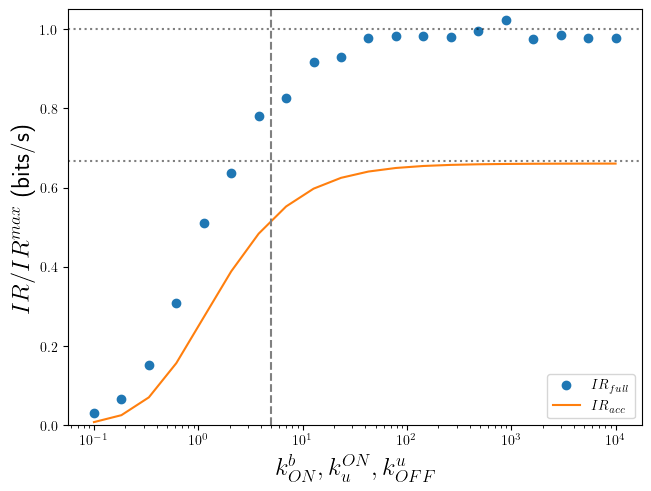

In [252]:
data_full = json.load(open('/home/tohme/.julia/dev/LLROpt/data/ir_full_scaling_output_20240725.json'))
data_acc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/ir_acc_scaling_output_20240725.json'))

nvals = len(data_full.keys())

xvals = np.logspace(-1, 4, 20)
# ir_full_pure = data["ir_full_pure"]
# ir_full_mix = data["ir_full_mix"]
# ir_acc_pure = data["ir_acc_pure"]
# ir_acc_mix = data["ir_acc_mix"]

fig, ax = plt.subplots(1,1, layout='constrained')

# ax.plot(xvals, ir_full_pure, 'o', color='C1', label=r"$IR_{f}^{pure}$")
# ax.plot(xvals, ir_full_mix, 'o', color='C2', label=r"$IR_{f}^{mix}$")

# ax.plot(xvals, ir_acc_pure, color='C1', label=r"$IR_{a}^{pure}$")
# ax.plot(xvals, ir_acc_mix, color='C2', label=r"$IR_{a}^{mix}$")
ax.plot(xvals, [data_full[str(i)] for i in range(1, nvals+1)], 'o', label=r"$IR_{full}$")
ax.plot(xvals, [2*data_acc[str(i)]/3 for i in range(1, nvals+1)], label=r"$IR_{acc}$")
ax.set_xlabel(r"$k_{ON}^b, k_{u}^{ON}, k_{OFF}^u$", fontsize=18)
ax.set_ylabel(r"$IR/IR^{max}$ (bits/s)", fontsize=18)
ax.axvline(x=5, linestyle='dashed', color='gray')
ax.axhline(y=1, linestyle='dotted', color='black', alpha=0.5)
ax.axhline(y=2/3, linestyle='dotted', color='black', alpha=0.5)
ax.legend()
ax.set_xscale('log')

ax.set_ylim(0, 1.05)

In [253]:
fig.savefig("plots/ir_limit_konb_kuon_koffu_large_notrescaled_20240725.pdf")

### maximizing $IR_{pure} + \beta IR_{mix}$

In [3]:
def f(x,g):
    a = 1/g
    b = 1-a/(1-a)
    if a >= 1/2:
        return (2*a-1)/(1-a)**2
    else:
        return (1-a)*a**(-1/(1-a))*np.sin(np.pi*a/(1-a))*x**b/np.pi

In [230]:
# dirname = '20241004/full'
# dirname = '20241111/ir-epsilon'
# dirname = '20241113/ir-dr'
dirname = '20241114/ir-epsilon-hernan'
whichf = "acc"
k, kg, kw = (122, 1, 1)
# xlim, ylim = (2, 2.4)
showbound = False

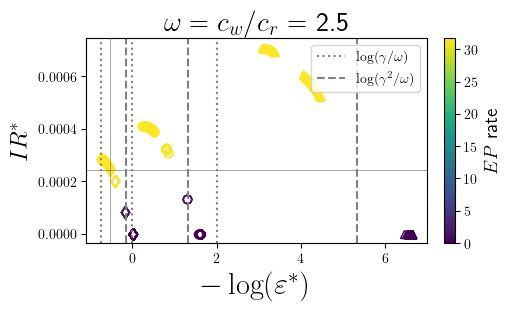

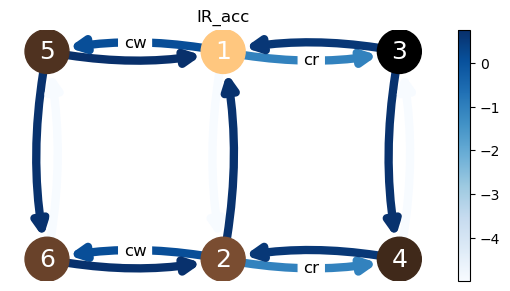

In [231]:
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
importlib.reload(plot)

paramfile = "params"
path = '/home/tohme/.julia/dev/LLROpt/data/'
params_acc = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

data_acc = {}
data_acc_proc = {}
ncpus = params_acc["ncpus"]
nbetas = params_acc["nparams"]
betas = params_acc["betas"]
gammas = params_acc["gammas"]
wvals = params_acc["wvals"]
nparams_per_cpu = int(nbetas/ncpus)

a = 3e-3        # um
D_tf = 7.4      # um^2/s
D_cplx = 0.1    # um^2/s
cr = 5.6         # um^-3
dc = 0.1 * cr
dl_tf = 4*a*D_tf
ub = 5
lb = 1e-5

winds = [kw-1]
g = gammas[kg-1]
w = wvals[kw-1]
cw = w*cr
x = cr / (cr+cw)

max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)
tau = (1/(1+w))*(1/(cr*dl_tf)+(1+w/g)/5)
max_ir_mix = 0.5 * (dc**2/(cr**2 + f(x,g)*(cr+cw)**2))/tau

for cpukey in range(1, ncpus + 1):
    data_acc_proc = json.load(open(path+'{}/ir_{}_mix_vs_pure_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

    for i in range(1, nparams_per_cpu+1):
        keyb = (cpukey - 1) * nparams_per_cpu + i
        data_acc[str(keyb)] = data_acc_proc[str(keyb)]

# max_irmix = data_acc[str(30)][str(kg)][str(kw)][8]
# max_irpure = data_acc[str(1)][str(kg)][str(kw)][9]
# irpure_max_irmix = data_acc[str(29)][str(kg)][str(kw)][9]

plt.rcParams['text.usetex'] = True

figplot, ax = plt.subplots(1,1, layout='constrained', figsize=(5,3))

colors = ['C{}'.format(i) for i in range(len(gammas))]
markers = ['d','o','^']
node_color = ""
epvals = np.zeros((len(gammas), nbetas))
cmap = plt.colormaps["viridis"]

for (i, gamma) in enumerate(gammas):
    for j in winds:

        keyg = str(i+1)
        keyw = str(j+1)

        xopt = np.array([data_acc[str(k)][keyg][keyw][:8] for k in np.arange(1, nbetas+1, 1)])
        ir_acc_mix = np.array([data_acc[str(k)][keyg][keyw][8] for k in np.arange(1, nbetas+1, 1)])
        ir_acc_pure = np.array([data_acc[str(k)][keyg][keyw][9] for k in np.arange(1, nbetas+1, 1)])
        # epvals[i] = np.array([data_acc[str(k)][keyg][keyw][12] for k in np.arange(1, nbetas+1, 1)])

        # for acc
        epvals[i] = np.array([data_acc[str(k)][keyg][keyw][10] for k in np.arange(1, nbetas+1, 1)])

        for x in range(nbetas):
            ax.plot(ir_acc_mix[x], 
                    ir_acc_pure[x], 
                    marker=markers[i], 
                    fillstyle='none',
                    color=cmap(epvals[i,x]), 
                    linestyle='none', 
                    markersize=6)

        ax.set_ylabel(r"$IR^*$", fontsize=18)
        ax.set_xlabel(r"$- \log(\varepsilon^*)$", fontsize=22)
        irvals = np.linspace(0, 2e-3, 50)

    ax.axvline(x=np.log2(gamma**2/w), linestyle='dashed', color='gray')
    ax.axvline(x=np.log2(gamma/w), linestyle='dotted', color='gray')

# ax.set_xticks(np.linspace(0,0.5,6))
# ax.set_xticklabels(np.round(np.linspace(0,0.5,6), 1), fontsize=12)
# ax.set_yticks(np.linspace(0,1,6))
# ax.set_yticklabels(np.round(np.linspace(0,1,6), 1), fontsize=12)
_=ax.set_title(r"$\omega = c_w/c_r$ = {}".format(w), fontsize=20)

# plot circuit
importlib.reload(plot)

xopt_acc = data_acc[str(k)][str(kg)][str(kw)][:8]
kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = xopt_acc
logrates2 = [kuoff+np.log10(g), kboff+np.log10(cw), kbon+np.log10(cw), kuon+np.log10(g), 
        konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]

edges = [(4,0), (0,4), (1,5), (5,1), (0,1), (0,2), (1,3),
         (1,0), (2,0), (2,3), (3,1), (3,2), (4,5), (5,4)]
# logrates2 = np.ones(14)*-5
# logrates2[0] = 2*dl_tf
# logrates2[2] = np.log(5)
# # logrates2[4] = np.log(5)
# logrates2[5] = dl_tf
# logrates2[9] = np.log(5)
# logrates2[10] = np.log(5)
# logrates2[13] = np.log(5)
wedges_acc = [(u,v,w) for ((u,v), w) in zip(edges, logrates2)]
wedges_acc_lin = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])

iedges = [(0,2), (1,3)]
on_ind = np.array([0,1,0,1,0,1])
Q = utils.build_mat(wedges_acc_lin, iedges, cr)
pss = ctmc.P_ss(Q)
pc = sum(pss[[0]])
# pc = 1

if showbound:
    # ax.axvline(x = pc/(1+w), linewidth=1, color="red", linestyle="dashed")
    ax.axvline(x = max_ir_mix/0.0020, linewidth=1, color="red", linestyle="dashed")
    # ax.text(pc/(1+w)+0.01,0.1,r"$\frac{\pi(1)}{1+w}$", fontsize=18, color="red")
h1 = mpatches.Patch(color=colors[j])  
wlabels = list(zip(*[(mpatches.Patch(color=colors[j]), 'w = {}'.format(w)) for (j,w) in enumerate(wvals)]))
gammalabels = list(zip(*[(Line2D([0], [0], linestyle='none', fillstyle='none',marker=markers[i], color="black"),r"$\gamma = {}$".format(round(g, 1))) for (i,g) in enumerate(gammas)]))

ax.legend(wlabels[0]+gammalabels[0], wlabels[1]+gammalabels[1], loc='lower right')
ax.legend(gammalabels[0], gammalabels[1], loc='upper right', fontsize=8)
ax.legend((Line2D([0], [0], linestyle='dotted', color='gray'),
           Line2D([0], [0], linestyle='dashed', color='gray')),
           (r"$\log(\gamma/\omega)$",r"$\log(\gamma^2/\omega)$"), loc='upper right') # (0.5,0.1)
# ax.set_ylim(0, ylim)
# ax.set_xlim(0, xlim)
ax.axhline(y = data_acc[str(k)][str(kg)][str(kw)][9], linewidth=0.5, color="gray")
ax.axvline(x = data_acc[str(k)][str(kg)][str(kw)][8], linewidth=0.5, color="gray")
cb = figplot.colorbar(plt.cm.ScalarMappable(norm=Normalize(0,max(epvals.flatten())), cmap=cmap),
                     ax=ax)

# drvals = np.linspace(-1, 2, 100)
# betavals = - np.tan(np.linspace(0,np.pi/1000,32))
# for b in betavals:
#     ax.plot(drvals, (drvals+1)*b+0.0017)

cb.set_label(label="$EP$ rate", fontsize=14)

G = nx.DiGraph()
for u, v, w in wedges_acc_lin:
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)]) for i in G.nodes()]

node_labels = {0: r'FU',
                1: r'NU',
                2: r'FBR',
                3: r'NBR',
                4: r'FBW',
                5: r'NBW'}

node_numbers = {0: r'1',
                1: r'2',
                2: r'3',
                3: r'4',
                4: r'5',
                5: r'6'}

input_labels = {(0,4):"cw",
                (0,2):"cr",
                (1,5):"cw",
                (1,3):"cr"}

figcirc, ax, G = plot.draw_circuit(wedges_acc,
                                   iedges, 
                                   node_labels=node_numbers, 
                                   input_labels=input_labels,
                                   bottom_set=[5,1,3],
                                   node_size=1000,
                                   node_color=node_color,
                                   title="IR_acc",
                                   dims=(5,2.8))

In [225]:
pss[3]

0.00024361775800809359

In [126]:
figplot.savefig("/home/tohme/phd/flython/plots/ir-epsilon-20241112.pdf")

In [87]:
dirname = '20241011/full'
whichf = "full"
k, kg, kw = (15, 2, 1)
xlim, ylim = (3e-3, 3e-3)
node_color = ""

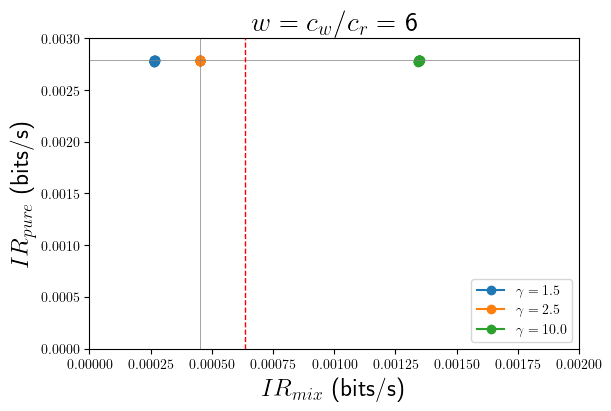

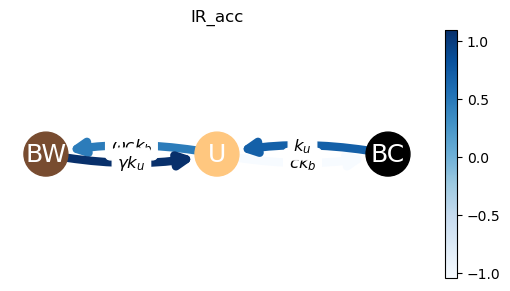

In [88]:
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
importlib.reload(plot)

path = '/home/tohme/.julia/dev/LLROpt/data/'
params_acc = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

data_acc = {}
data_acc_proc = {}
ncpus = params_acc["ncpus"]
nbetas = params_acc["nparams"]
betas = params_acc["betas"]
gammas = params_acc["gammas"]
wvals = params_acc["wvals"]
nparams_per_cpu = int(nbetas/ncpus)

winds = [kw-1]
g = gammas[kg-1]
w = wvals[kw-1]
cw = w*cr
x = cr/(cw+cr)
tau = (1/(1+w))*(1/(cr*dl_tf)+(1+w/g)/5)
max_ir_mix = 0.5 * (dc**2/(cr**2 + f(x,g)*(cr+cw)**2))/tau

for cpukey in range(1, ncpus + 1):
    data_acc_proc = json.load(open(path+'{}/ir_{}_mix_vs_pure_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

    for i in range(1, nparams_per_cpu+1):
        keyb = (cpukey - 1) * nparams_per_cpu + i
        data_acc[str(keyb)] = data_acc_proc[str(keyb)]

max_irpure = data_acc[str(1)][str(kg)][str(kw)][3]

plt.rcParams['text.usetex'] = True

fig, ax = plt.subplots(1,1, layout='constrained', figsize=(6,4))

colors = ['C{}'.format(i) for i in range(len(gammas))]

for (i, gamma) in enumerate(gammas):
    for j in winds:

        keyg = str(i+1)
        keyw = str(j+1)

        xopt = np.array([data_acc[str(k)][keyg][keyw][:2] for k in np.arange(1, nbetas+1, 1)])
        ir_acc_mix = np.array([data_acc[str(k)][keyg][keyw][2] for k in np.arange(1, nbetas+1, 1)])
        ir_acc_pure = np.array([data_acc[str(k)][keyg][keyw][3] for k in np.arange(1, nbetas+1, 1)])

        ax.plot( ir_acc_mix, ir_acc_pure, color=colors[i], marker='o', linestyle='none', markersize=6)

        ax.set_ylabel(r"$IR_{pure}$ (bits/s)", fontsize=18)
        ax.set_xlabel(r"$IR_{mix}$ (bits/s)", fontsize=18)
        irvals = np.linspace(0, 2e-3, 50)

h1 = mpatches.Patch(color=colors[j])  
wlabels = list(zip(*[(mpatches.Patch(color=colors[j]), 'w = {}'.format(w)) for (j,w) in enumerate(wvals)]))
gammalabels = list(zip(*[(Line2D([0], [0], color=colors[i], marker='o'),r"$\gamma = {}$".format(round(g, 1))) for (i,g) in enumerate(gammas)]))
ax.legend(wlabels[0]+gammalabels[0], wlabels[1]+gammalabels[1], loc='lower right')
ax.legend(gammalabels[0], gammalabels[1], loc='lower right')
ax.set_ylim(0, 3e-3)
ax.set_xlim(0, 2e-3)
ax.axhline(y = data_acc[str(k)][str(kg)][str(kw)][3], linewidth=0.5, color="gray")
ax.axvline(x = data_acc[str(k)][str(kg)][str(kw)][2], linewidth=0.5, color="gray")

ax.axvline(x = max_ir_mix, linewidth=1, color="red", linestyle="dashed")
# ax.axhline(y = ir_full_pure[k], linewidth=1, color="gray", linestyle="dashed")
# ax.axvline(x = ir_full_mix[k], linewidth=1, color="gray", linestyle="dashed")
_=ax.set_title(r"$w = c_w/c_r$ = {}".format(w), fontsize=20)
# ax.axvline(x=dcr_mle)

# plot circuit
importlib.reload(plot)

a = 3e-3        # um
D_tf = 7.4      # um^2/s
D_cplx = 0.1    # um^2/s
cr = 5.6         # um^-3
dc = 0.1 * cr
cw = w * cr
dl_tf = 4*a*D_tf
ub = 5
lb = 1e-5
max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)

xopt_acc = data_acc[str(k)][str(kg)][str(kw)][:2]
kb, ku = xopt_acc
logrates2 = [kb, ku, kb+np.log10(cw), ku+np.log10(g)]

edges = [(0,1),(1,0),(0,2),(2,0)]
wedges_acc = [(u,v,w) for ((u,v), w) in zip(edges, logrates2)]
wedges_acc_lin = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])

iedges = [(0,1)]
on_ind = np.array([0,1,1])
Q = utils.build_mat(wedges_acc_lin, iedges, cr)
pss = ctmc.P_ss(Q)
pc = sum(pss[[0]])
kbl = 10**kb
kul = 10**ku

G = nx.DiGraph()
for u, v, w in wedges_acc_lin:
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)]) for i in G.nodes()]


node_labels = {0: r'U',
                1: r'BC',
                2: r'BW'}

input_labels = {(0,1):"$ck_b$",
                (0,2):"$\omega c k_b$",
                (1,0):"$k_u$",
                (2,0):"$\gamma k_u$"}

fig, ax, G = plot.draw_circuit(wedges_acc,
                            iedges, 
                            node_labels=node_labels, 
                            input_labels=input_labels,
                            bottom_set=[2,0,1],
                            node_size=1000,
                            node_color=node_color,
                            title="IR_acc",
                            dims=(5,2.8))

## Handcrafted circuits

In [23]:
dirname = '20241022/dr_limits/'
fname = "dr_max_full_noac.json"
k, kg, kw = (1, 3, 3)
xlim, ylim = (1e-3, 2.5e-3)
node_color = ""
acc = False

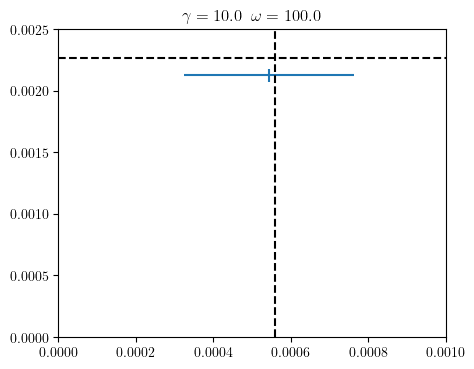

In [24]:
path = '/home/tohme/.julia/dev/LLROpt/data/'
data = json.load(open(path+dirname+fname))

logrates = data["1"][str(kg)][str(kw)][:-8]
irmix_mean = data["1"][str(kg)][str(kw)][-8]
irpure_mean = data["1"][str(kg)][str(kw)][-7]
irmix_stdev = data["1"][str(kg)][str(kw)][-6]
irpure_stdev = data["1"][str(kg)][str(kw)][-5]
g = data["1"][str(kg)][str(kw)][-2]
w = data["1"][str(kg)][str(kw)][-1]
cw = w*cr
x = cr / (cr+cw)

max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)
tau = (1/(1+w))*(1/(cr*dl_tf)+(1+w/g)/5)
max_ir_mix = 0.5 * (dc**2/(cr**2 + f(x,g)*(cr+cw)**2))/tau

plt.rcParams['text.usetex'] = True
fig, ax = plt.subplots(1,1,figsize=(5,4))

ax.errorbar(irmix_mean, irpure_mean, irpure_stdev, irmix_stdev)
ax.axhline(y=max_ir_full, linestyle="dashed", color="black")
ax.axvline(x=max_ir_mix, linestyle="dashed", color="black")
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)
ax.set_title(r"$\gamma={}\;\; \omega={}$".format(g, round(w, 1)))

if acc:
    edges = [(4,0), (0,4), (1,5), (5,1), (0,1), (0,2), (1,3),
             (1,0), (2,0), (2,3), (3,1), (3,2), (4,5), (5,4)]
    iedges = [(0,2), (1,3)]
    on_ind = np.array([0,1,0,1,0,1])
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = logrates
    logrates2 = [kuoff+np.log10(g), kboff+np.log10(cw), kbon+np.log10(cw), kuon+np.log10(g), 
        konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]
else:
    edges = [(0,1),(1,0),(0,2),(2,0)]
    iedges = [(0,1)]
    on_ind = np.array([0,1,1])
    kb, ku = logrates
    logrates2 = [kb, ku, kb+np.log10(cw), ku+np.log10(g)]


wedges = [(u,v,w) for ((u,v), w) in zip(edges, logrates2)]
wedges_lin = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])
Q = utils.build_mat(wedges_lin, iedges, cr)
pss = ctmc.P_ss(Q)


G = nx.DiGraph()
for u, v, w in wedges_lin:
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)]) for i in G.nodes()]

if acc:

    node_labels = {0: r'FU',
                    1: r'NU',
                    2: r'FBR',
                    3: r'NBR',
                    4: r'FBW',
                    5: r'NBW'}

    node_numbers = {0: r'1',
                    1: r'2',
                    2: r'3',
                    3: r'4',
                    4: r'5',
                    5: r'6'}

    input_labels = {(0,4):"cw",
                    (0,2):"cr",
                    (1,5):"cw",
                    (1,3):"cr"}

else:
    node_labels = {0: r'U',
                    1: r'BC',
                    2: r'BW'}

    input_labels = {(0,1):"$ck_b$",
                    (0,2):"$\omega c k_b$",
                    (1,0):"$k_u$",
                    (2,0):"$\gamma k_u$"}

    # fig, ax, G = plot.draw_circuit(wedges_acc,
    #                             iedges, 
    #                             node_labels=node_labels, 
    #                             input_labels=input_labels,
    #                             bottom_set=[2,0,1],
    #                             node_size=1000,
    #                             node_color=node_color,
    #                             title="IR_acc",
    #                             dims=(5,2.8))

### Exploring optimal circuit statistics

In [485]:
k, kg, kw = (1,2,2)

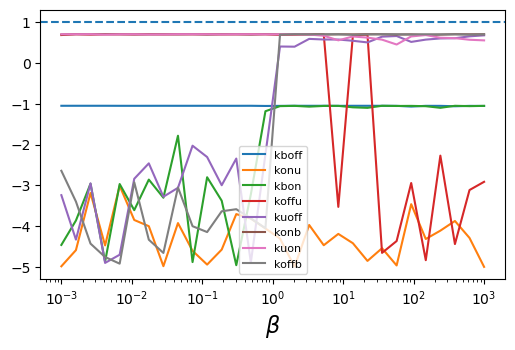

In [684]:
pons = np.zeros(nbetas)
tbs = np.zeros(nbetas)
tons = np.zeros(nbetas)
toffs = np.zeros(nbetas)
sharps = np.zeros(nbetas)
vars = np.zeros(nbetas)
ir_mixs = np.zeros(nbetas)
lrspec = np.zeros(nbetas)
ir_pures = np.zeros(nbetas)
logrates_all = np.zeros((8, nbetas))
on_ind_pure = [0,1,0,1]
edges_pure = [(0,2),(0,1),(1,3),(1,0),(2,0),(2,3),(3,1),(3,2)]
g = gammas[kg-1]
w = wvals[kw-1]

for k, beta in enumerate(betas):
    logrates = data_acc[str(k+1)][str(kg)][str(kw)][:8]
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = logrates
    logrates2 = [kuoff+np.log10(g), kboff+np.log10(cw), kbon+np.log10(cw), kuon+np.log10(g), 
        konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]
    wedges_acc = np.array([(u,v,10**w) for ((u,v), w) in zip(edges_pure, logrates)])
    wedges_acc2 = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])
    Q = utils.build_mat(wedges_acc2, iedges, cr)
    pss = ctmc.P_ss(Q)
    pons[k] = ctmc.pi_on(wedges_acc2, iedges, cr, on_ind)
    lrspec[k] = np.log2((pss[3])/(pss[5]))
    ton, toff = ctmc.mean_fpt_part(wedges_acc2, iedges, cr, on_ind)
    tbs[k] = ton+toff
    tons[k] = ton
    toffs[k] = toff
    sharps[k] = ctmc.sharpness(wedges_acc2, iedges, cr, on_ind)
    ir_mixs[k] = ctmc.ir_acc(wedges_acc2, iedges, cr, dc, on_ind)
    ir_pures[k] = ctmc.ir_acc(wedges_acc, iedges, cr, dc, on_ind_pure)
    vars[k] = ctmc.var(wedges_acc2, iedges, cr, on_ind)
    logrates_all[:,k] = logrates

fig, ax = plt.subplots(1,1, figsize=(6,3.5))

# axr = ax.twinx()

# ax.plot(betas, ir_mixs)
# ax.plot(betas, ir_pures)
# ax.plot(betas, sharps)
# ax.plot(betas, lrspec)
# ax.plot(betas, tbs)
# ax.plot(betas, tons)
# ax.plot(betas, toffs)

ax.plot(betas, logrates_all[0,:], label="kboff")
ax.plot(betas, logrates_all[1,:], label="konu")
ax.plot(betas, logrates_all[2,:], label="kbon")   #
ax.plot(betas, logrates_all[3,:], label="koffu")  #
ax.plot(betas, logrates_all[4,:], label="kuoff")  #
ax.plot(betas, logrates_all[5,:], label="konb")
ax.plot(betas, logrates_all[6,:], label="kuon")
ax.plot(betas, logrates_all[7,:], label="koffb")  #

# axr.plot(betas, pons, color='C3')
# axr.plot(betas, vars, color='C4')
ax.axhline(y=np.log2(g/w), linestyle='dashed')

ax.set_xscale('log')
# axr.set_ylabel(r"$p_{ON}$", fontsize=16)
# ax.set_ylabel(r"$\tau_{B}$", fontsize=16)
ax.set_xlabel(r"$\beta$", fontsize=16)
ax.legend(loc='lower center', fontsize=8)

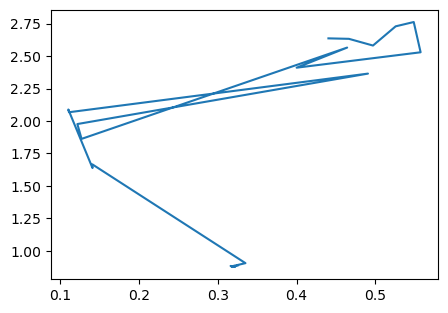

In [635]:
fig, ax = plt.subplots(1,1, figsize=(5,3.5))

ax.plot(pons, tbs)

# Multiple binding sites

## 2 binding sites

## 6 binding sites

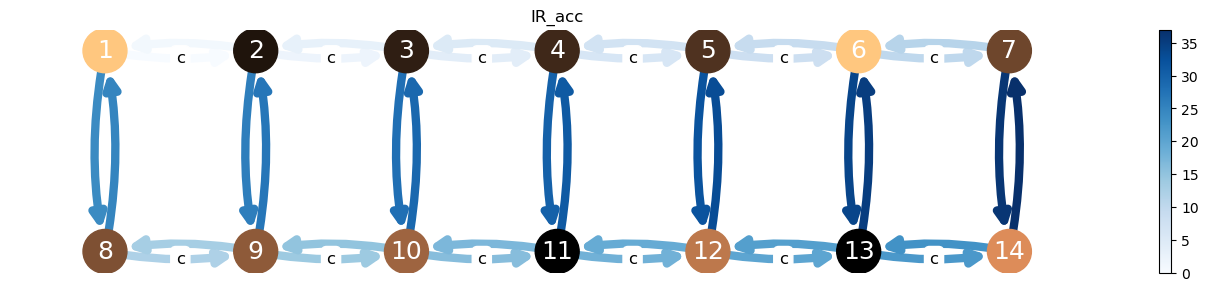

(<Figure size 1200x280 with 2 Axes>,
 <Axes: title={'center': 'IR_acc'}>,
 <networkx.classes.digraph.DiGraph at 0x70d6cfe95350>)

In [687]:
import networkx as nx
importlib.reload(plot)

edges = [(1 ,2 ), (2 ,1 ),
         (2 ,3 ), (3 ,2 ),
         (3 ,4 ), (4 ,3 ),
         (4 ,5 ), (5 ,4 ),
         (5 ,6 ), (6 ,5 ),
         (6 ,7 ), (7 ,6 ),
         (8 ,9 ), (9 ,8 ),
         (9 ,10), (10,9 ),
         (10,11), (11,10),
         (11,12), (12,11),
         (12,13), (13,12),
         (13,14), (14,13),
         (1 ,8 ), (8 ,1 ),
         (2 ,9 ), (9 ,2 ),
         (3 ,10), (10,3 ),
         (4 ,11), (11,4 ),
         (5 ,12), (12,5 ),
         (6 ,13), (13,6 ),
         (7 ,14), (14,7 )]

weights = np.arange(len(edges))
wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
iedges = [(i,i+1) for i in range(1,14) if i != 7]
on_ind = np.concatenate((np.zeros(7), np.ones(7)))
node_labels = dict(zip(range(1,15), range(1,15)))
node_color = [20,2,3,4,5,20,7,8,9,10,0,12,0,14]
input_labels = dict(zip(iedges, ['c']*14))
bottom_set = range(8,15)
node_size=1000

plot.draw_circuit(wedges, 
                  iedges, 
                  node_labels=node_labels, 
                  input_labels=input_labels,
                  bottom_set=bottom_set,
                  node_size=node_size,
                  node_color=node_color,
                  title="IR_acc",
                  dims=(12,2.8))

In [688]:
kb = 3
dirname1 = '20241002/6bs'
node_color=""
which_ir = "acc"

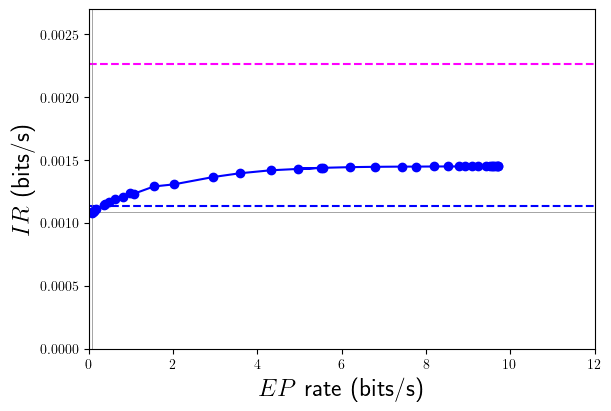

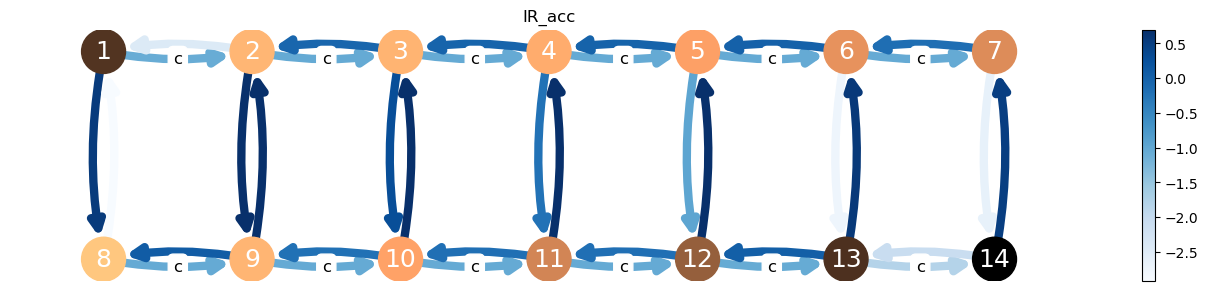

In [689]:
import matplotlib.pyplot as plt
importlib.reload(plot)

########## 6 bs

params_acc1 = json.load(open(path+'{}/params.json'.format(dirname1)))
data_acc = {}
data_acc_proc1 = {}
ncpus = params_acc1["ncpus"]
nparams = params_acc1["nparams"]
betakeys = np.arange(1, nparams+1)
nparams_per_cpu = int(nparams/ncpus)

for cpukey in range(1, ncpus+1):
    data_acc_proc1 = json.load(open(path+'{}/ir_{}_vs_ep_pareto_pid{}.json'.format(dirname1, which_ir, cpukey)))

    for k in range(1, nparams_per_cpu+1):
        betakey = (cpukey - 1)*nparams_per_cpu + k
        data_acc[betakey] = data_acc_proc1[str(betakey)]

nvals = len(data_acc.keys())
irvals_acc1 = [data_acc[i][-2] for i in betakeys]
# irstdev_acc1 = [data_acc[i][-1] for i in betakeys]
epvals_acc1 = [data_acc[i][-1] for i in betakeys]

plt.rcParams['text.usetex'] = True

fig1, ax = plt.subplots(1,1, layout='constrained', figsize=(6,4))

ax.errorbar(epvals_acc1, irvals_acc1, linestyle='solid',marker='o', color='blue')
# ax.plot(epvals_acc2, irvals_acc2, marker='o', color='green')
ax.axhline(y=0.0022614, color='magenta', linestyle='dashed')
ax.axhline(y=0.0022614/2, color='blue', linestyle='dashed')
ax.axhline(y = data_acc[kb][-2], linewidth=0.5, color="gray")
ax.axvline(x = data_acc[kb][-1], linewidth=0.5, color="gray")
ax.set_ylim(0,0.0027)
ax.set_xlim(0, 12)
ax.set_ylabel(r"$IR$ (bits/s)", fontsize=18)
ax.set_xlabel(r"$EP$ rate (bits/s)", fontsize=18)

weights = np.array(data_acc[kb][:len(edges)])
wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])

wedges_lin = np.array([(u-1,v-1,10**w) for ((u,v),w) in zip(edges, weights)])
iedges_py = [(u-1,v-1) for (u,v) in iedges]
Q = utils.build_mat(wedges_lin, iedges_py, cr)
pss = ctmc.P_ss(Q)

G = nx.DiGraph()
for u, v, w in wedges:
    # print("edge: ({},{})".format(u, v), "weight: {}".format(w))
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)-1]) for i in G.nodes()]

fig2, ax, _ = plot.draw_circuit(
    wedges, 
    iedges,
    node_labels=node_labels, 
    input_labels=input_labels,
    bottom_set=bottom_set,
    node_size=node_size,
    node_color=node_color,
    title="IR_acc",
    dims=(12,2.8)
)

In [497]:
fig1.savefig('plots/6bs_irfull_ir_vs_ep_not_converging_20241005.pdf')
fig2.savefig('plots/6bs_circuit_not_converged.pdf')

# Better estimator for V

### Testing estimators with a real Gaussian process

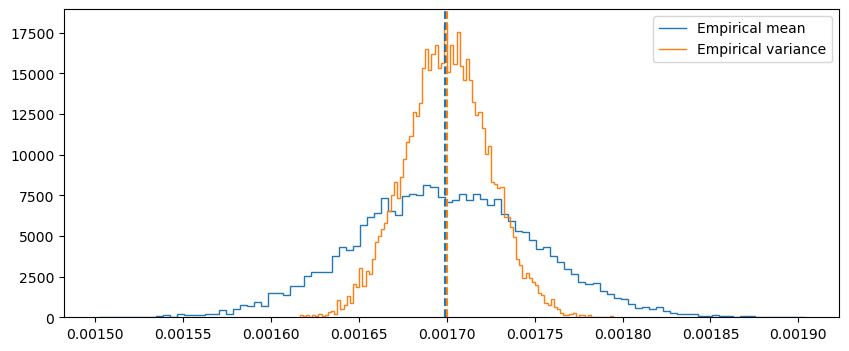

In [107]:
date = 20240822
data1 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/empirical_mean_estimator.json'.format(date)))
data2 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/empirical_variance_estimator.json'.format(date)))
# data3 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/20240809/maximum_likelihood_estimator.json'))

fig, ax = plt.subplots(1,1, figsize=(10,4))

h1, edges1 = np.histogram(data1, bins=100, density=True)
h2, edges2 = np.histogram(data2, bins=100, density=True)
# h3, edges3 = np.histogram(data3, bins=30, density=True)

ax.stairs(h1, edges1, label='Empirical mean')
ax.stairs(h2, edges2, label='Empirical variance')
# ax.stairs(h3, edges3, label='MLE given V=D')

ax.axvline(x=np.mean(data1), linestyle='dashed', color='C0')
ax.axvline(x=np.mean(data2), linestyle='dashed', color='C1')
# ax.axvline(x=np.mean(data3), linestyle='dashed', color='C2')
# ax.set_xlim(80, 120)

ax.legend()

In [151]:
fig.savefig('plots/estimators_comparison_20240809.pdf')

### How gaussian are LLR increments?

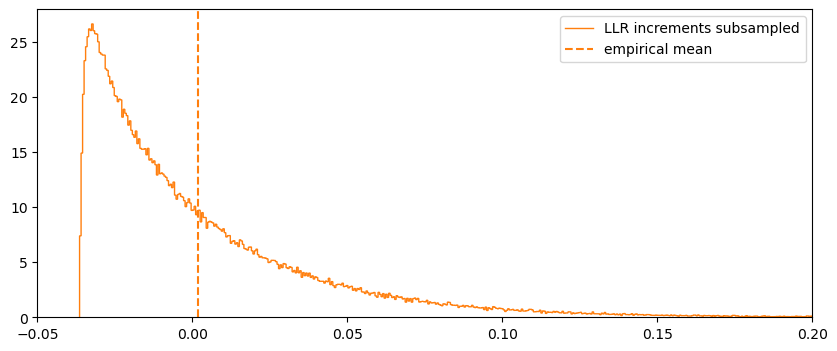

In [5]:
date = 20240822
# data1 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/llr_incrs.json'.format(date)))
data2 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/llr_incrs_sub.json'.format(date)))

c = 5.6
kb = 0.0888
kon = 5
ku = 5
koff = 5
n = 10000000
k = 5000000
dt = (1/(c*kb) + 1/kon + 1/ku + 1/koff) * (n/k) / 2
V = 0.0017
sigma = np.sqrt(2*V*dt)
xvals = np.linspace(V*dt-4*sigma, V*dt+4*sigma, 1000)

fig, ax = plt.subplots(1,1, figsize=(10,4))

# h1, edges1 = np.histogram(data1, bins=100, density=True)
h2, edges2 = np.histogram(np.array(data2)/dt, bins=1000, density=True)

# ax.stairs(h1, edges1, label='LLR increments', color='C0')
ax.stairs(h2, edges2, label='LLR increments subsampled', color='C1')

# ax.axvline(x=np.mean(data1), linestyle='dashed', color='C0')
ax.axvline(x=np.mean(data2)/dt, linestyle='dashed', color='C1', label="empirical mean")

norm = np.exp(-(xvals - V*dt)**2/(2*sigma**2)) / np.sqrt(2*np.pi*sigma**2)
# ax.plot(xvals/dt, norm, color='C2')
# ax.axvline(x=V*dt, linestyle='dashed', color='C2', label="true mean")
ax.set_xlim(-0.05, 0.2)
ax.legend()

In [18]:
print("empirical D:", np.var(data2)/(2*dt))
print("empirical V:", np.mean(data2)/dt)

empirical D: 0.0018980577150951967
empirical V: 0.0017631688717462905


### Testing mean and var estimators with our LLR process

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


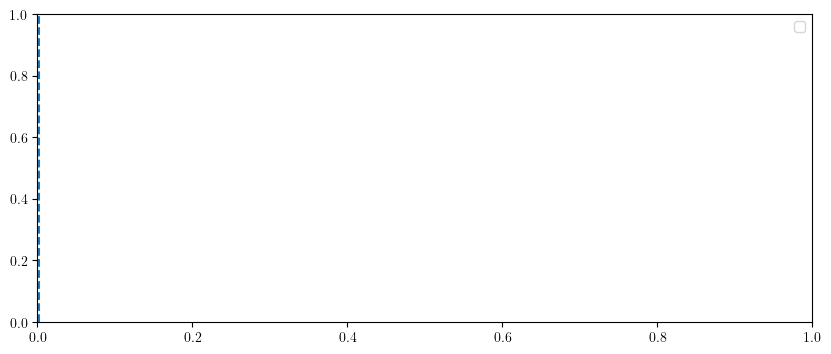

In [48]:
# date = 20241103
date = 20241111
data1 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_mean_estimator.json'.format(date)))
# data2 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_variance_estimator.json'.format(date)))

fig, ax = plt.subplots(1,1, figsize=(10,4))

h1, edges1 = np.histogram(data1, bins=50, density=True)
# h2, edges2 = np.histogram(data2, bins=50, density=True)

ax.stairs(h1, edges1, label='Empirical mean')
# ax.stairs(h2, edges2, label='Empirical variance')

ax.axvline(x=np.mean(data1), linestyle='dashed', color='C0')
# ax.axvline(x=np.mean(data2), linestyle='dashed', color='C1')

ax.legend()

In [184]:
dirname = 'plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig(dirname+'/ir_full_mean_and_variance_estimators_subsamp_5.pdf')

### Testing V=D and decision-time distribution

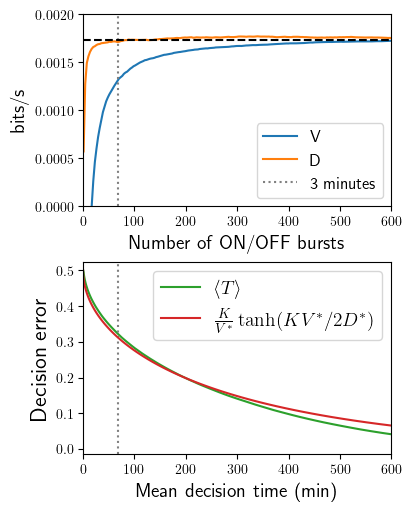

In [18]:
dirname = "20241103/"
# dirname = "20241102/max_iracc_circuit/" 
# dirname = "20241102/max_IR_equilibrium_circuit/"
path = '/home/tohme/.julia/dev/LLROpt/data/'
data1 = json.load(open(path+'{}ir_full_samples.json'.format(dirname)))
data2 = json.load(open(path+'{}stop_times_llr.json'.format(dirname)))
data3 = json.load(open(path+'{}stop_times_gp.json'.format(dirname)))

n = 5000
ntimes = len(data1)
nruns = len(data1[0])
nerrs = len(data2)

c = 5.6
kb = 0.0888
kon = 5
ku = 5
koff = 5
taub = (1/(c*kb) + 1/kon + 1/ku + 1/koff)
times = np.linspace(taub, n*taub/8, ntimes)
errs = np.linspace(0.5, 1e-2, nerrs)

V = np.mean(np.array(data1), axis=1)
D = np.var(np.array(data1) * np.sqrt(times)[:,None], axis=1) / 2

plt.rcParams['text.usetex'] = True
fig, ax = plt.subplots(2,1, figsize=(4,5), layout="constrained")

ax[0].plot(times/taub, V, label="V")
ax[0].plot(times/taub, D, label="D")
ax[0].set_ylim(0, 0.002)
ax[0].set_xlim(0, 600)
ax[0].axvline(x=180/taub, linestyle="dotted", color="gray", label="3 minutes")
ax[0].axhline(y=0.001728, linestyle="dashed", color="black")
ax[0].set_xlabel("Number of ON/OFF bursts", fontsize=14)
ax[0].set_ylabel(r"bits/s", fontsize=14)
ax[0].legend(fontsize=12)

mean_stoptimes = np.mean(np.array(data2), axis=1)
Ks = np.log((1-errs)/errs)

ax[1].plot(mean_stoptimes/taub, errs, label=r"$\langle T \rangle$", color="C2")
ax[1].set_xlabel("Mean decision time (min)", fontsize=14)
ax[1].set_ylabel("Decision error", fontsize=16)
ax[1].set_xlim(0, 600)
ax[1].axvline(x=180/taub, linestyle="dotted", color="gray")
key = 21
ax[1].plot(Ks * np.tanh(Ks*V[key]/(2*D[key]))/(V[key]*taub), 
           errs, label="$\\frac{K}{V^*}\\tanh(KV^*/2D^*)$", color="C3")
ax[1].legend(fontsize=14)

In [14]:
V[21]

0.0013035889579539797

In [19]:
import os

path = 'plots/'+dirname
if not os.path.exists(path):
    os.makedirs(path)

fig.savefig('plots/{}V_and_D_pre_asymptotics.pdf'.format(dirname))

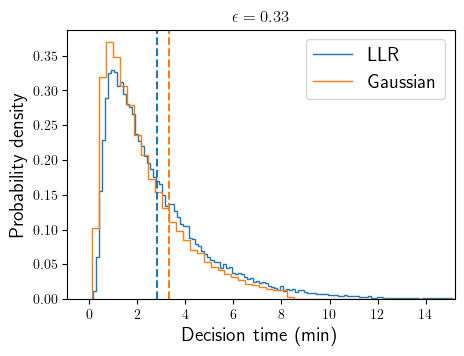

In [37]:
fig, ax = plt.subplots(1,1, figsize=(5,3.5))

ierrs = [35]
# ax.set_title("Decision time density")
ax.set_xlabel("Decision time (min)", fontsize=14)
ax.set_ylabel("Probability density", fontsize=14)

for (i, ierr) in enumerate(ierrs):
    ax.set_title(r"$\epsilon = {}$".format(round(errs[ierr],2)))
    h1, edges1 = np.histogram(np.array(data2[ierr])/60, bins=200, density=True)
    h2, edges2 = np.histogram(np.array(data3[ierr])/60, bins=200, density=True)

    ax.stairs(h1, edges1, label="LLR")
    ax.stairs(h2, edges2, label="Gaussian")

    ax.axvline(x=np.mean(data2[ierr])/60, linestyle='dashed', color="C{}".format(i))
    ax.axvline(x=np.mean(data3[ierr])/60, linestyle='dashed', color="C{}".format(i+1))

r,l = ax.get_xlim()
ax.set_xlim(r/3, l/4)
ax.legend(fontsize=14)

In [116]:
print("<T>_LLR / <T>_GP - 1 ~", (np.mean(data2[ierr])/np.mean(data3[ierr]) - 1) * 100, "%")

<T>_LLR / <T>_GP - 1 ~ 11.927870349568614 %


Text(0, 0.5, 'ET')

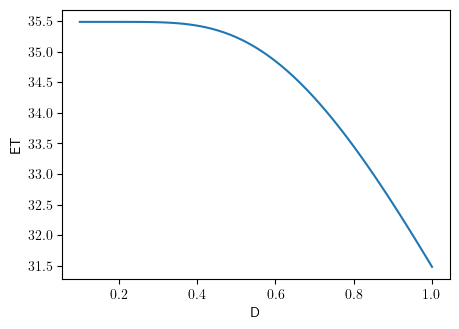

In [155]:
# fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

K = 10
vs = np.linspace(0.1, 1, 100)
ds = np.linspace(0.1, 1, 100)
x, y = np.meshgrid(vs, ds)
z = (K / x) * np.tanh(K*x/(2*y))
# ax.plot_surface(x, y, z)
# ax.set_xlabel("V")
# ax.set_ylabel("D")

fig, ax = plt.subplots(1,1,figsize=(5,3.5))

vx = vs[20]
c = 1
# vx = ds * c
ax.plot(ds, (K / vx) * np.tanh(K*vx/(2*ds)))
ax.set_xlabel("D")
ax.set_ylabel("ET")

### Improving decision-time statistics

### RMC estimator (importance sampling)

state of affairs as of 20240927:
- RMC code is wrong (doesn't agree with old code's estimate)
- about 8x slower
- uses 3x as much memory

wrong: 
it's not calculating the same thing. i'm using RS as matrices, assuming the traj starts in the same partition, there's plenty of room for bugs.

slow:
seems to be a problem with get_residence_time and generate. the ll code seems to be fast.

memory:
fine-tuning.

Léo Regnier: use a score that adds more weight to the trajectories that contribute the most variance to your estimator. This may be different than RMC if you're only interested in the first moment. you need to make sure your resampling obeys detailed balance - ergodicity

# IR limits

# Inferring circuits from traces